In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import astropy.constants as cte
import astropy.units as un
import func_for_boots

In [2]:
c_kms = cte.c.to(un.km / un.s).value

Ha = 6562.79
Hb = 4861.35

lineas = {
    "Ha": {"nplot":r"H$_{\alpha}$", "rest": Ha, "fixed_window": 135, "lim_inf": 6400, "lim_sup": 7800},
    "Hb": {"nplot":r"H$_{\beta}$" , "rest": Hb, "fixed_window": 150, "lim_inf": 4635, "lim_sup": 5050}}

model_dir = "/Volumes/discoSSD/WD_models/koester2_3"
all_models = func_for_boots.load_koester_models(model_dir)

modelos_aumentados = func_for_boots.aumentar_resolucion_models(all_models)

model_grid_Ha = func_for_boots.convolution(modelos_aumentados, lineas, 'Ha', min_wave_search=Ha)
model_grid_Hb = func_for_boots.convolution(modelos_aumentados, lineas, 'Hb', min_wave_search=Hb)

--------------  INFO STARS -------------- 
* Central values come from the normalization notebook and topcat xmatch between centrales Ha, Hb and v_helio. In this case vhelio = 0, since spec were corrected previously. Parameters come from GF21 and MJ
  
  

In [3]:
info = pd.read_csv('info_stars_P116_centrales_GF')
nombres_info_list = info['nombre_1'].tolist()
targets = info['target'].tolist()
vel_helio_list = info['vhelio'].tolist()
central_Ha_list = info['central_1'].tolist()
central_Hb_list = info['central_2'].tolist()
teff_ext = info['teff_H'].tolist()
logg_ext = info['logg_H'].tolist()
eteff_ext = info['eteff_H'].tolist()
elogg_ext = info['elogg_H'].tolist()

In [4]:
def stats(x):
    m_a = np.percentile(x, 50)
    l_a, u_a = np.percentile(x, [16, 84])
    eup_a, elow_a = u_a - m_a, m_a - l_a
    err_a = max(elow_a, eup_a)
    return m_a, l_a, u_a, eup_a, elow_a

In [5]:
def plot_histogramas(nombre):
    path_Ha = f'boots2206_p116/wds/{nombre}/Ha'
    path_Hb = f'boots2206_p116s/wds/{nombre}/Hb'

    # RVs
    
    boots_rv_Ha = pd.read_csv(f'{path_Ha}/bootstrap_rv_500.txt')
    boots_rv_Hb = pd.read_csv(f'{path_Hb}/bootstrap_rv_500.txt')

    m_Ha_rv, l_Ha_rv, u_Ha_rv, eup_Ha_rv, elow_Ha_rv = stats(boots_rv_Ha)
    m_Hb_rv, l_Hb_rv, u_Hb_rv, eup_Hb_rv, elow_Hb_rv = stats(boots_rv_Hb)

    fig, (ax1, ax2) = plt.subplots(1,2, figsize=(10, 4))
    plt.suptitle(nombre)
    
    ax1.hist(boots_rv_Ha,bins=20, color='salmon', edgecolor='gray')
    ax1.axvline(m_Ha_rv,c='k',lw=2)
    ax1.axvline(l_Ha_rv,c='k',ls='--',lw=2, label=r' perc. 16')
    ax1.axvline(u_Ha_rv,c='k',ls='-.',lw=2, label=r' perc. 84')
    ax1.set_xlabel('RV (km/s)')
    ax1.set_ylabel('Frequency')
    ax1.set_title(r'H$_{\alpha}$')

    ax2.hist(boots_rv_Hb,bins=20, color='salmon', edgecolor='gray')
    ax2.axvline(m_Hb_rv,c='k',lw=2)
    ax2.axvline(l_Hb_rv,c='k',ls='--',lw=2, label=r' perc. 16')
    ax2.axvline(u_Hb_rv,c='k',ls='-.',lw=2, label=r' perc. 84')
    ax2.set_xlabel('RV (km/s)')
    ax2.set_title(r'H$_{\beta}$')

    plt.legend()
    plt.savefig(f'{path_Ha}/rv_dist.png')
    
    # Teffs

    boots_teff_Ha = pd.read_csv(f'{path_Ha}/bootstrap_teff_500.txt')
    boots_teff_Hb = pd.read_csv(f'{path_Hb}/bootstrap_teff_500.txt')

    m_Ha_teff, l_Ha_teff, u_Ha_teff, eup_Ha_teff, elow_Ha_teff = stats(boots_teff_Ha)
    m_Hb_teff, l_Hb_teff, u_Hb_teff, eup_Hb_teff, elow_Hb_teff = stats(boots_teff_Hb)

    fig, (ax1, ax2) = plt.subplots(1,2, figsize=(10, 4))
    plt.suptitle(nombre)

    ax1.hist(boots_teff_Ha, color='salmon', edgecolor='gray')
    ax1.axvline(m_Ha_teff,c='k',lw=2)
    ax1.axvline(l_Ha_teff,c='k',ls='--',lw=2, label=r' perc. 16')
    ax1.axvline(u_Ha_teff,c='k',ls='-.',lw=2, label=r' perc. 84')
    ax1.set_xlabel('Teff (km/s)')
    ax1.set_ylabel('Frequency')
    ax1.set_title(r'H$_{\alpha}$')

    ax2.hist(boots_teff_Hb, color='salmon', edgecolor='gray')
    ax2.axvline(m_Hb_teff,c='k',lw=2)
    ax2.axvline(l_Hb_teff,c='k',ls='--',lw=2, label=r' perc. 16')
    ax2.axvline(u_Hb_teff,c='k',ls='-.',lw=2, label=r' perc. 84')
    ax2.set_xlabel('Teff (km/s)')
    ax2.set_title(r'H$_{\beta}$')

    plt.legend()
    plt.savefig(f'{path_Ha}/teff_dist.png')

    #loggs
    boots_logg_Ha = pd.read_csv(f'{path_Ha}/bootstrap_logg_500.txt')
    boots_logg_Hb = pd.read_csv(f'{path_Hb}/bootstrap_logg_500.txt')

    m_Ha_logg, l_Ha_logg, u_Ha_logg, eup_Ha_logg, elow_Ha_logg = stats(boots_logg_Ha)
    m_Hb_logg, l_Hb_logg, u_Hb_logg, eup_Hb_logg, elow_Hb_logg = stats(boots_logg_Hb)

    fig, (ax1, ax2) = plt.subplots(1,2, figsize=(10, 4))
    plt.suptitle(nombre)

    ax1.hist(boots_logg_Ha, color='salmon', edgecolor='gray')
    ax1.axvline(m_Ha_logg,c='k',lw=2)
    ax1.axvline(l_Ha_logg,c='k',ls='--',lw=2, label=r' perc. 16')
    ax1.axvline(u_Ha_logg,c='k',ls='-.',lw=2, label=r' perc. 84')
    ax1.set_xlabel('logg (km/s)')
    ax1.set_ylabel('Frequency')
    ax1.set_title(r'H$_{\alpha}$')

    ax2.hist(boots_logg_Hb, color='salmon', edgecolor='gray')
    ax2.axvline(m_Hb_logg,c='k',lw=2)
    ax2.axvline(l_Hb_logg,c='k',ls='--',lw=2, label=r' perc. 16')
    ax2.axvline(u_Hb_logg,c='k',ls='-.',lw=2, label=r' perc. 84')
    ax2.set_xlabel('logg (km/s)')
    ax2.set_title(r'H$_{\beta}$')

    plt.legend()
    plt.savefig(f'{path_Ha}/logg_dist.png')

    plt.show()
    

In [6]:
# 1. Definir rutas (Leemos tu archivo base central, pero consolidamos la salida)
path_central = 'info_stars_P116_centrales_GF' 
path_salida = 'initial_guesses_22.csv'  # <- Redirigido al archivo consolidado unificado

# Leer el archivo central original
df_central = pd.read_csv(path_central, sep=',') 

columna_estrella = 'nombre_1' 

# 2. Inicializar las nuevas columnas si no existen
nuevas_columnas = [
    'Ha_m_rv', 'Ha_max_err_rv', 'Hb_m_rv', 'Hb_max_err_rv',
    'Ha_m_teff', 'Ha_max_err_teff', 'Hb_m_teff', 'Hb_max_err_teff',
    'Ha_m_logg', 'Ha_max_err_logg', 'Hb_m_logg', 'Hb_max_err_logg'
]
for col in nuevas_columnas:
    if col not in df_central.columns:
        df_central[col] = None

# 3. Bucle de procesamiento de Bootstrap
for nombre in nombres_info_list:
    
    if nombre not in df_central[columna_estrella].values:
        print(f"Advertencia: {nombre} no se encuentra en el archivo central. Saltando...")
        continue

    path_Ha = f'boots2206_p116_plots/wds/{nombre}/Ha'
    path_Hb = f'boots2206_p116_plots/wds/{nombre}/Hb'

    # Cargar archivos de bootstrap
    boots_rv_Ha = pd.read_csv(f'{path_Ha}/bootstrap_rv_500.txt')
    boots_rv_Hb = pd.read_csv(f'{path_Hb}/bootstrap_rv_500.txt')

    boots_teff_Ha = pd.read_csv(f'{path_Ha}/bootstrap_teff_500.txt')
    boots_teff_Hb = pd.read_csv(f'{path_Hb}/bootstrap_teff_500.txt')

    boots_logg_Ha = pd.read_csv(f'{path_Ha}/bootstrap_logg_500.txt')
    boots_logg_Hb = pd.read_csv(f'{path_Hb}/bootstrap_logg_500.txt')

    # Estadísticas para RV
    m_Ha_rv, l_Ha_rv, u_Ha_rv, eup_Ha_rv, elow_Ha_rv = stats(boots_rv_Ha)
    m_Hb_rv, l_Hb_rv, u_Hb_rv, eup_Hb_rv, elow_Hb_rv = stats(boots_rv_Hb)

    Ha_max_err_rv = max(eup_Ha_rv, elow_Ha_rv, 0.01)
    Hb_max_err_rv = max(eup_Hb_rv, elow_Hb_rv, 0.01)

    # Estadísticas para Teff
    m_Ha_teff, l_Ha_teff, u_Ha_teff, eup_Ha_teff, elow_Ha_teff = stats(boots_teff_Ha)
    m_Hb_teff, l_Hb_teff, u_Hb_teff, eup_Hb_teff, elow_Hb_teff = stats(boots_teff_Hb)

    Ha_max_err_teff = max(eup_Ha_teff, elow_Ha_teff, 100)
    Hb_max_err_teff = max(eup_Hb_teff, elow_Hb_teff, 100)

    # Estadísticas para logg
    m_Ha_logg, l_Ha_logg, u_Ha_logg, eup_Ha_logg, elow_Ha_logg = stats(boots_logg_Ha)
    m_Hb_logg, l_Hb_logg, u_Hb_logg, eup_Hb_logg, elow_Hb_logg = stats(boots_logg_Hb)

    Ha_max_err_logg = max(eup_Ha_logg, elow_Ha_logg, 0.01)
    Hb_max_err_logg = max(eup_Hb_logg, elow_Hb_logg, 0.01)

    # Identificar la estrella y rellenar celdas en el DataFrame
    idx = df_central[columna_estrella] == nombre
    
    df_central.loc[idx, 'Ha_m_rv'] = m_Ha_rv
    df_central.loc[idx, 'Ha_max_err_rv'] = Ha_max_err_rv
    df_central.loc[idx, 'Hb_m_rv'] = m_Hb_rv
    df_central.loc[idx, 'Hb_max_err_rv'] = Hb_max_err_rv

    df_central.loc[idx, 'Ha_m_teff'] = m_Ha_teff
    df_central.loc[idx, 'Ha_max_err_teff'] = Ha_max_err_teff
    df_central.loc[idx, 'Hb_m_teff'] = m_Hb_teff
    df_central.loc[idx, 'Hb_max_err_teff'] = Hb_max_err_teff

    df_central.loc[idx, 'Ha_m_logg'] = m_Ha_logg
    df_central.loc[idx, 'Ha_max_err_logg'] = Ha_max_err_logg
    df_central.loc[idx, 'Hb_m_logg'] = m_Hb_logg
    df_central.loc[idx, 'Hb_max_err_logg'] = Hb_max_err_logg

# 4. GUARDAR EN EL ARCHIVO CSV SEGURO DE DESTINO
df_central.to_csv(path_salida, index=False, sep=',')
print(f"¡Hecho! Los nuevos parámetros calculados fueron guardados en '{path_salida}'.")

¡Hecho! Los nuevos parámetros calculados fueron guardados en 'initial_guesses_22.csv'.


In [9]:
def rv_thin(nombre, use):
    fila_estrella = df_central[df_central['nombre_1'] == nombre]
    
    target = fila_estrella['target'].iloc[0]
    OB = fila_estrella['OB'].iloc[0]
    date = fila_estrella['date'].iloc[0]
    
    central_Ha = float(fila_estrella['central_1'].iloc[0])
    central_Hb = float(fila_estrella['central_2'].iloc[0])
    vhelio = float(fila_estrella['vhelio'].iloc[0])
    teff_GF = float(fila_estrella['teff_H'].iloc[0])
    eteff_GF = float(fila_estrella['eteff_H'].iloc[0])
    logg_GF = float(fila_estrella['logg_H'].iloc[0])
    elogg_GF = float(fila_estrella['elogg_H'].iloc[0])
    
    rv_Ha = float(fila_estrella['Ha_m_rv'].iloc[0])
    erv_Ha = float(fila_estrella['Ha_max_err_rv'].iloc[0])
    teff_Ha = float(fila_estrella['Ha_m_teff'].iloc[0])
    eteff_Ha = float(fila_estrella['Ha_max_err_teff'].iloc[0])
    logg_Ha = float(fila_estrella['Ha_m_logg'].iloc[0])
    elogg_Ha = float(fila_estrella['Ha_max_err_logg'].iloc[0])
    
    rv_Hb = float(fila_estrella['Hb_m_rv'].iloc[0])
    erv_Hb = float(fila_estrella['Hb_max_err_rv'].iloc[0])
    teff_Hb = float(fila_estrella['Hb_m_teff'].iloc[0])
    eteff_Hb = float(fila_estrella['Hb_max_err_teff'].iloc[0])
    logg_Hb = float(fila_estrella['Hb_m_logg'].iloc[0])
    elogg_Hb = float(fila_estrella['Hb_max_err_logg'].iloc[0])

    print(rv_Ha, rv_Hb)

    lineas_a_graficar = ['Ha', 'Hb']
    
    fig, axes = plt.subplots(2, 1, figsize=(8, 10))

    datos_retorno = None

    rvs = []
    ervs = []
    chis2s = []

    for i, l_iter in enumerate(lineas_a_graficar):
      
        ax = axes[i]
        
        if l_iter == 'Ha':
            model_grid, central = model_grid_Ha, central_Ha
            rv_center, rv_err = rv_Ha, erv_Ha
            rest = Ha
            linea_plot = r'H$_{\alpha}$'
        if l_iter == 'Hb':
            model_grid, central = model_grid_Hb, central_Hb
            rv_center, rv_err = rv_Hb, erv_Hb
            rest = Hb
            linea_plot = r'H$_{\beta}$'

        rv_test = np.arange(rv_center - 10*rv_err, rv_center + 10*rv_err, 0.04)
        step = np.median(np.diff(rv_test))

        wave, flux = func_for_boots.find_spec(nombre, l_iter)

        eflux = np.full_like(flux, np.std(flux[0:700]))
        mask_obs = (wave >= (central-15)) & (wave <= (central+15))
        wave_masked_obs, flux_masked_obs, eflux_masked_obs = wave[mask_obs], flux[mask_obs], eflux[mask_obs]

        datos_por_linea = {"linea": l_iter, "fixed_window": lineas[l_iter]["fixed_window"], "line_center_obs": central}

        if use == 'GF':
            # Usa los datos globales GF para ambas líneas
            wm, fm = func_for_boots.safe_get_model(datos_por_linea, l_iter, model_grid, teff_GF, logg_GF)
            teff_plot, logg_plot = teff_GF, logg_GF
            
        elif use == 'MJ':
            # Separa estrictamente: cada línea con su propia Teff y logg
            if l_iter == 'Ha':
                wm, fm = func_for_boots.safe_get_model(datos_por_linea, l_iter, model_grid, teff_Ha, logg_Ha)
                teff_plot, logg_plot = teff_Ha, logg_Ha
            elif l_iter == 'Hb':
                wm, fm = func_for_boots.safe_get_model(datos_por_linea, l_iter, model_grid, teff_Hb, logg_Hb)
                teff_plot, logg_plot = teff_Hb, logg_Hb

        def inner_compute_chi2(rv_arr):
            chi2s = []
            for rv in rv_arr:
                wm_s = wm * (1 + rv/c_kms)
                m_mod = ((wm_s >= wave_masked_obs.min()) & (wm_s <= wave_masked_obs.max()))
                fm_i = np.interp(wave_masked_obs, wm_s[m_mod], fm[m_mod])
                chi2s.append(np.nansum(((flux_masked_obs - fm_i) / eflux_masked_obs)**2))
            return np.array(chi2s)

        chi2s = inner_compute_chi2(rv_test)
        i_min = np.argmin(chi2s)

        if i_min < 5 or i_min > len(rv_test)-6:
            rv_center = rv_test[i_min]
            rv_test = np.arange(rv_center - 20, rv_center + 20, 0.04)
            chi2s = inner_compute_chi2(rv_test)
            i_min = np.argmin(chi2s)

        N_window = 150
        i_inf, i_sup = max(0, i_min - N_window), min(len(rv_test), i_min + N_window + 1)
        rv_fit, chi2_fit = rv_test[i_inf:i_sup], chi2s[i_inf:i_sup]
        A, B, C = np.polyfit(rv_fit, chi2_fit, 2)
        
        min_rv_array = rv_fit[np.argmin(chi2_fit)]
        min_rv_parab = -B / (2*A)
        error_min_rv_parab = np.sqrt(1/A)
        print(nombre, l_iter, min_rv_array,error_min_rv_parab)
        chi2_best_red = np.min(chi2s) / (len(flux_masked_obs) - 1)
        rvs.append(min_rv_array)
        ervs.append(error_min_rv_parab)
        chis2s.append(chi2_best_red)
        print('wave',wave)

        ax.plot(wave - rest , flux, 'gray', lw=.8, label='Obs')
        ax.plot(wm - rest, fm, 'b', lw=1.5, alpha=0.5, label='model')
        wm_shifted_best = wm * (1 + min_rv_parab/c_kms)
        ax.plot(wm_shifted_best - rest, fm, 'r', lw=1.5, label='shifted model')
        
        
        plt.suptitle(f'{nombre}', fontsize=15)
        ax.set_ylabel('Normalized flux', fontsize=15)
        ax.set_xlim(-15, +15)

        if nombre == 'cleaned_corr_spec4498551_20251025T001253572':
            ax.set_xlim(-30, +30)
        
        if i == 0:
            ax.legend(loc='upper right', fontsize=15)
        else:
            ax.set_xlabel(r'$\lambda - \lambda_0$ (Å)', fontsize=15)
     
        # 2. SECCIÓN MODIFICADA: Anotación de Teff y logg para AMBOS paneles
        # Saldrá teff_Ha/logg_Ha en el plot de Ha, y teff_Hb/logg_Hb en el de Hb
        ax.annotate(f'Teff: {teff_plot:.0f} K - logg: {logg_plot:.2f}', 
                    xy=(0.55, 0.1), xycoords='axes fraction', fontsize=14)

        # Anotación de la velocidad radial calculada
        ax.annotate(rf'RV {linea_plot}: {(min_rv_array + vhelio):.2f} $\pm$ {error_min_rv_parab:.2f} km/s', 
                    xy=(0.05, 0.9), xycoords='axes fraction', fontsize=15)
        
        # SI ESTA ES LA LÍNEA QUE PIDIÓ EL USUARIO, GUARDAMOS EL RETORNO

        #if l_iter == linea:
        #    datos_retorno = (vhelio, (min_rv_array+vhelio), error_min_rv_parab, chi2_best_red)

    #ax.set_xlabel(r'$\lambda - \lambda_0$ (Å)', fontsize=15)
    ax.set_xlabel(r'$\lambda - \lambda_0$', fontsize=15)
    plt.tight_layout()
    plt.savefig(f'resultados_plot/{nombre}_{use}.png')
    plt.show()

    print('-------------------------------')

    return rvs, ervs, chis2s

    



76.0 75.0
cleaned_corr_spec4498301_20251226T041344694 Ha 72.71999999999879 3.0257028712004015
wave 0       6400.020460
1       6400.055614
2       6400.091257
3       6400.126412
4       6400.161567
           ...     
6813    6639.844593
6814    6639.879747
6815    6639.914902
6816    6639.950057
6817    6639.985212
Name: wave, Length: 6818, dtype: float64
cleaned_corr_spec4498301_20251226T041344694 Hb 73.71999999999896 4.841167427378748
wave 0       4790.018583
1       4790.047391
2       4790.076686
3       4790.105982
4       4790.135278
           ...     
8901    5049.877985
8902    5049.907281
8903    5049.936088
8904    5049.965384
8905    5049.994680
Name: wave, Length: 8906, dtype: float64


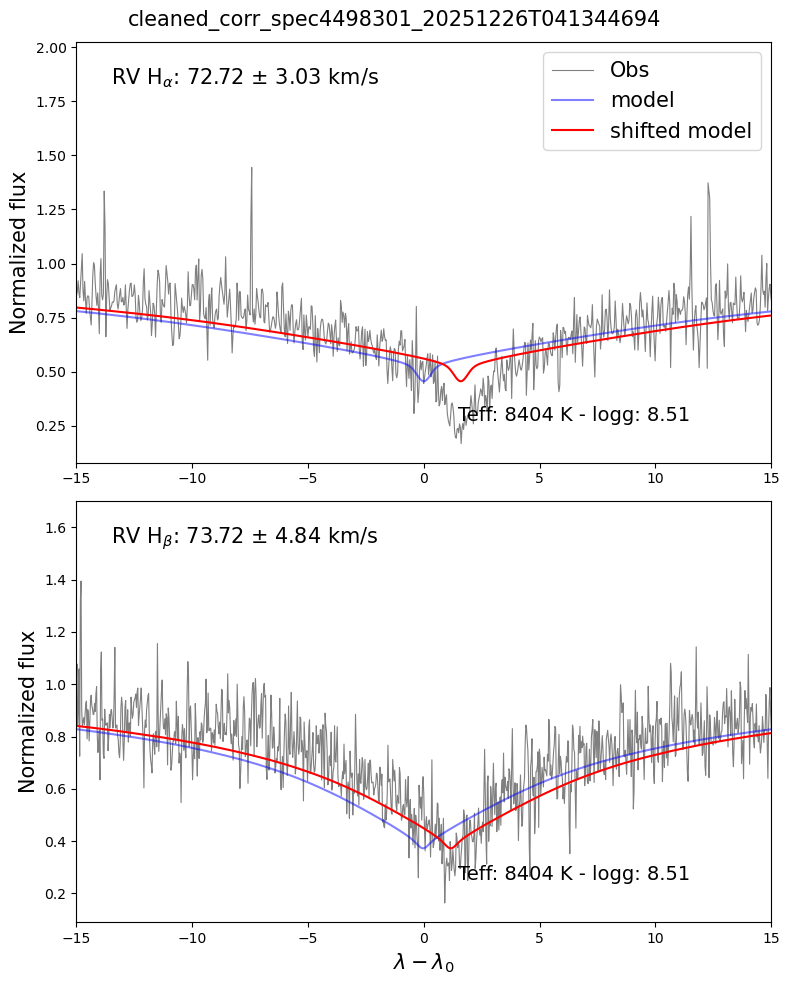

-------------------------------
76.0 75.0
cleaned_corr_spec4498301_20251226T041344694 Ha 75.11999999999874 3.1419984911237244
wave 0       6400.020460
1       6400.055614
2       6400.091257
3       6400.126412
4       6400.161567
           ...     
6813    6639.844593
6814    6639.879747
6815    6639.914902
6816    6639.950057
6817    6639.985212
Name: wave, Length: 6818, dtype: float64
cleaned_corr_spec4498301_20251226T041344694 Hb 74.95999999999893 4.049393581481499
wave 0       4790.018583
1       4790.047391
2       4790.076686
3       4790.105982
4       4790.135278
           ...     
8901    5049.877985
8902    5049.907281
8903    5049.936088
8904    5049.965384
8905    5049.994680
Name: wave, Length: 8906, dtype: float64


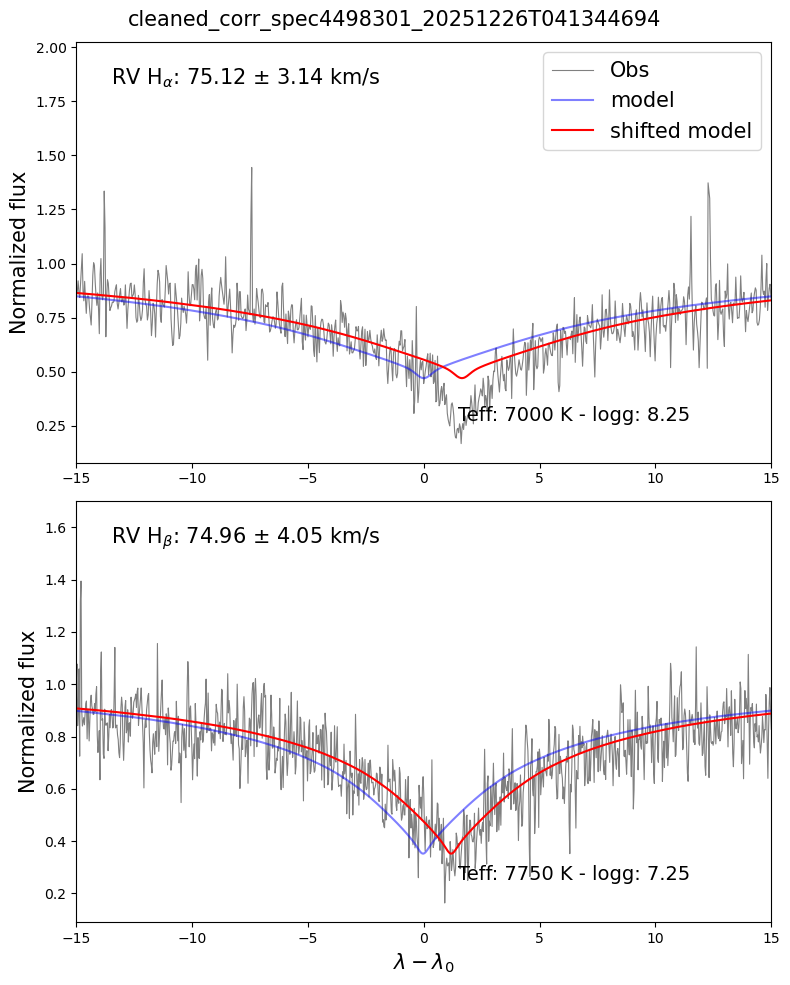

-------------------------------
Datos de ajuste (GF y MJ) guardados para: cleaned_corr_spec4498301_20251226T041344694
-12.0 -12.0
cleaned_corr_spec4498820_20251025T005108897 Ha -11.520000000000437 1.9853369762420303
wave 0       6400.0180
1       6400.0530
2       6400.0884
3       6400.1240
4       6400.1590
          ...    
6806    6639.8320
6807    6639.8670
6808    6639.9023
6809    6639.9375
6810    6639.9727
Name: wave, Length: 6811, dtype: float64
cleaned_corr_spec4498820_20251025T005108897 Hb -10.60000000000067 5.6387827531052155
wave 0       4790.0040
1       4790.0330
2       4790.0625
3       4790.0920
4       4790.1206
          ...    
8882    5049.8780
8883    5049.9070
8884    5049.9365
8885    5049.9660
8886    5049.9950
Name: wave, Length: 8887, dtype: float64


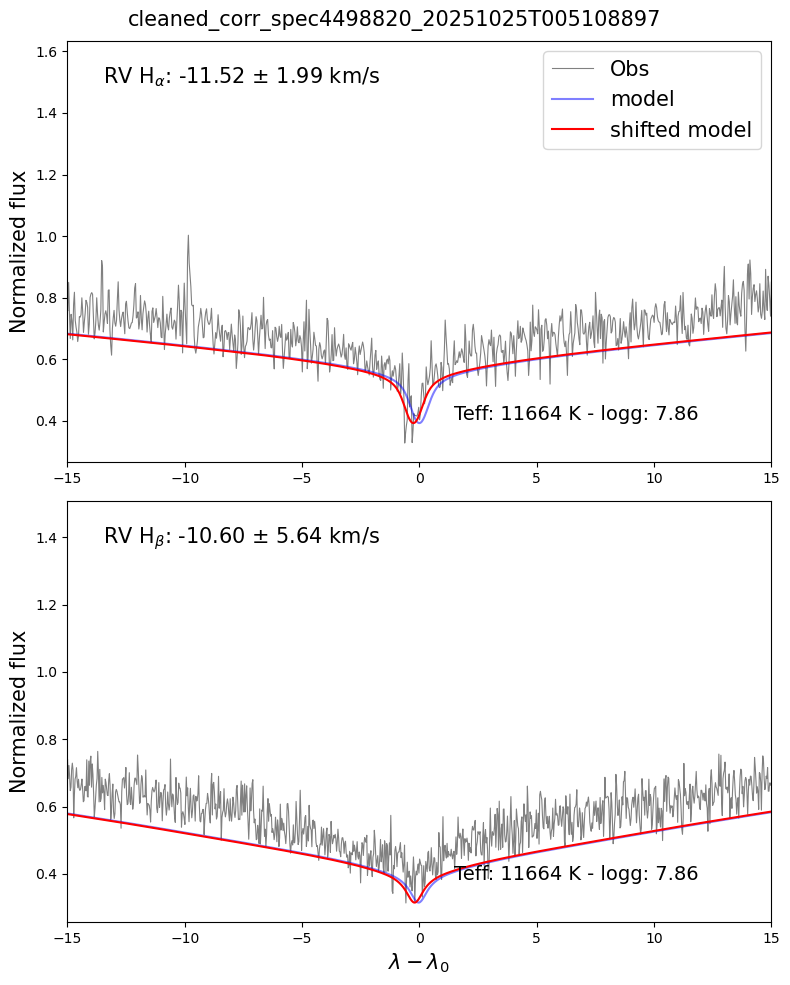

-------------------------------
-12.0 -12.0
cleaned_corr_spec4498820_20251025T005108897 Ha -12.080000000000425 1.9565345604309217
wave 0       6400.0180
1       6400.0530
2       6400.0884
3       6400.1240
4       6400.1590
          ...    
6806    6639.8320
6807    6639.8670
6808    6639.9023
6809    6639.9375
6810    6639.9727
Name: wave, Length: 6811, dtype: float64
cleaned_corr_spec4498820_20251025T005108897 Hb -12.360000000000632 4.916469840678477
wave 0       4790.0040
1       4790.0330
2       4790.0625
3       4790.0920
4       4790.1206
          ...    
8882    5049.8780
8883    5049.9070
8884    5049.9365
8885    5049.9660
8886    5049.9950
Name: wave, Length: 8887, dtype: float64


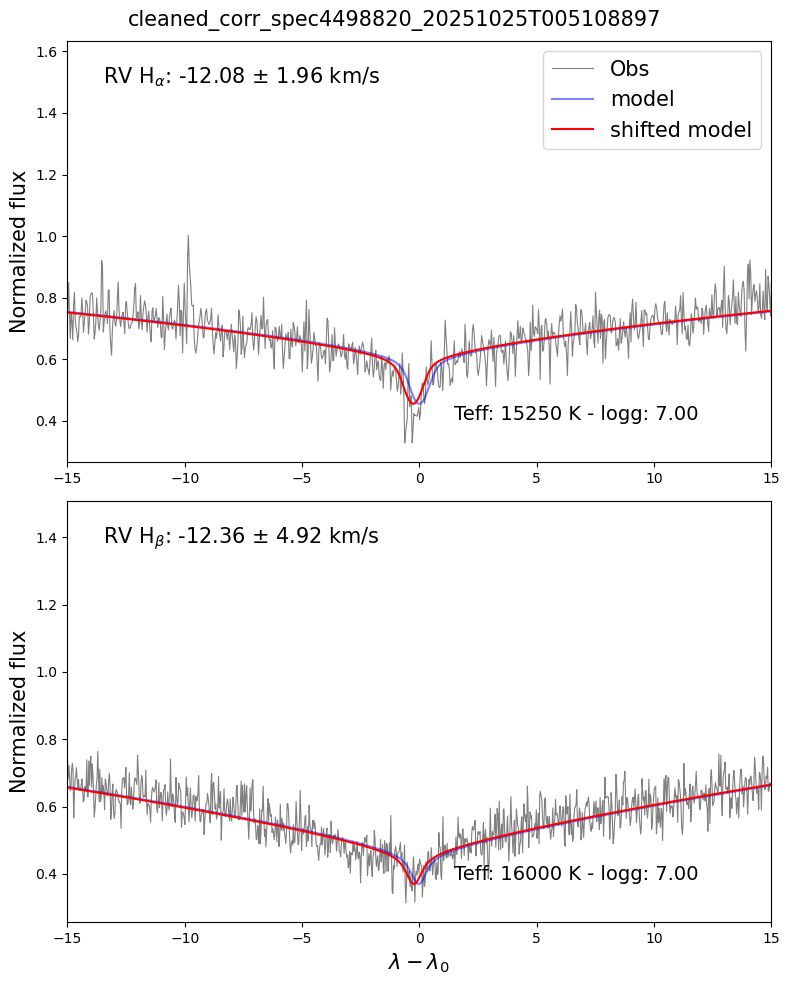

-------------------------------
Datos de ajuste (GF y MJ) guardados para: cleaned_corr_spec4498820_20251025T005108897
34.0 51.0
cleaned_corr_spec4498436_20251117T031453492 Ha 24.760000000000026 3.0142586108893497
wave 0       6400.034625
1       6400.069782
2       6400.104938
3       6400.140583
4       6400.175740
           ...     
6786    6639.832339
6787    6639.867984
6788    6639.903140
6789    6639.938297
6790    6639.973942
Name: wave, Length: 6791, dtype: float64
cleaned_corr_spec4498436_20251117T031453492 Hb 48.15999999999942 7.639489071267207
wave 0       4790.014276
1       4790.043573
2       4790.072870
3       4790.102168
4       4790.131465
           ...     
8841    5049.855639
8842    5049.884937
8843    5049.914234
8844    5049.943531
8845    5049.972828
Name: wave, Length: 8846, dtype: float64


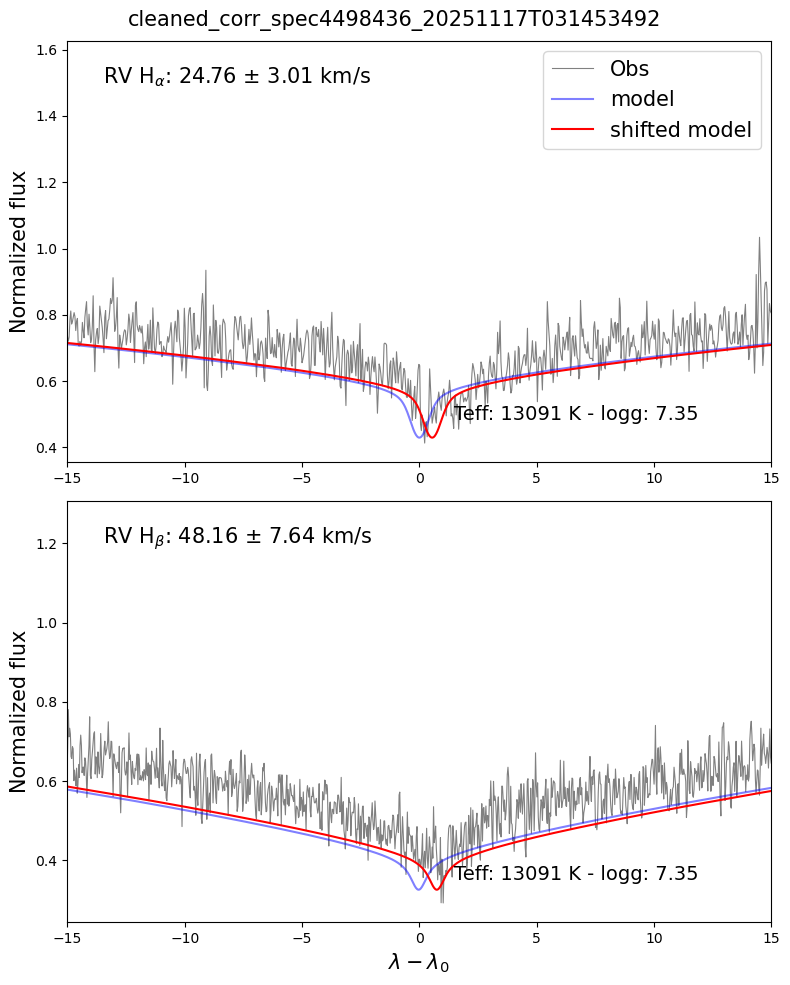

-------------------------------
34.0 51.0
cleaned_corr_spec4498436_20251117T031453492 Ha 34.320000000000036 3.9730557432438136
wave 0       6400.034625
1       6400.069782
2       6400.104938
3       6400.140583
4       6400.175740
           ...     
6786    6639.832339
6787    6639.867984
6788    6639.903140
6789    6639.938297
6790    6639.973942
Name: wave, Length: 6791, dtype: float64
cleaned_corr_spec4498436_20251117T031453492 Hb 51.11999999999936 5.592897041008236
wave 0       4790.014276
1       4790.043573
2       4790.072870
3       4790.102168
4       4790.131465
           ...     
8841    5049.855639
8842    5049.884937
8843    5049.914234
8844    5049.943531
8845    5049.972828
Name: wave, Length: 8846, dtype: float64


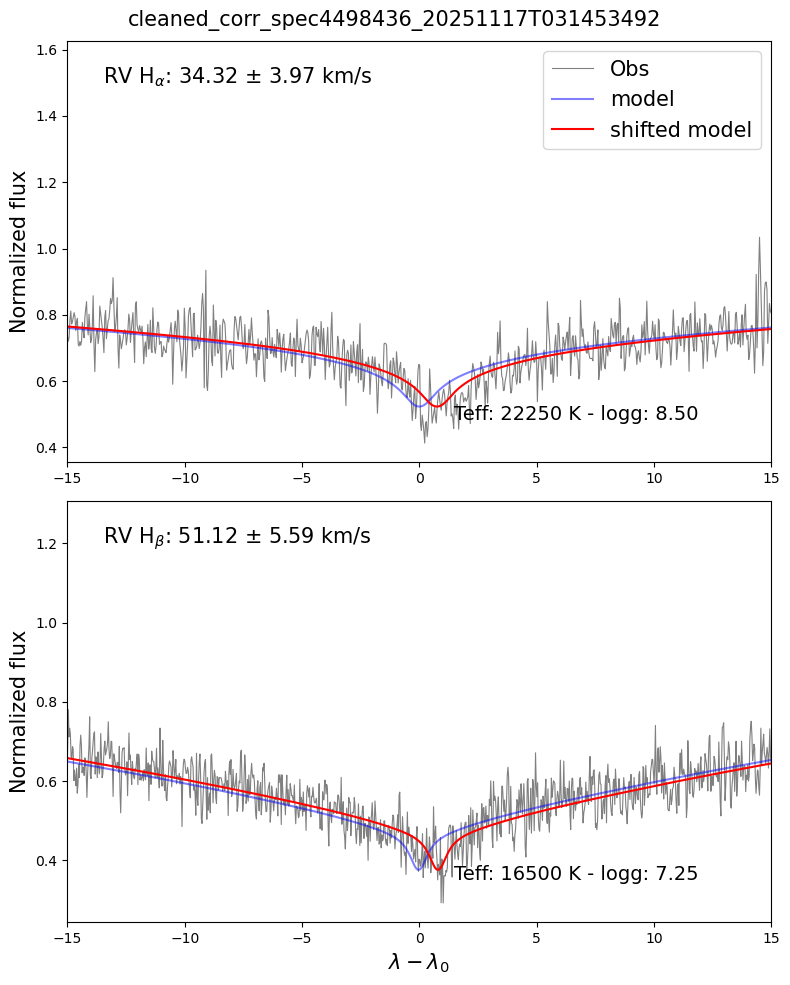

-------------------------------
Datos de ajuste (GF y MJ) guardados para: cleaned_corr_spec4498436_20251117T031453492
52.0 64.0
cleaned_corr_spec3119716_20211021T074457426 Ha 52.319999999999354 2.4776334493743906
wave 0       6400.020421
1       6400.053466
2       6400.086511
3       6400.119556
4       6400.152601
           ...     
7255    6639.862157
7256    6639.895202
7257    6639.928247
7258    6639.961292
7259    6639.994337
Name: wave, Length: 7260, dtype: float64
cleaned_corr_spec3119716_20211021T074457426 Hb 62.999999999998956 6.3238327173454065
wave 0       4790.020506
1       4790.048173
2       4790.075840
3       4790.103507
4       4790.131173
           ...     
9392    5049.866247
9393    5049.893914
9394    5049.921580
9395    5049.949247
9396    5049.976914
Name: wave, Length: 9397, dtype: float64


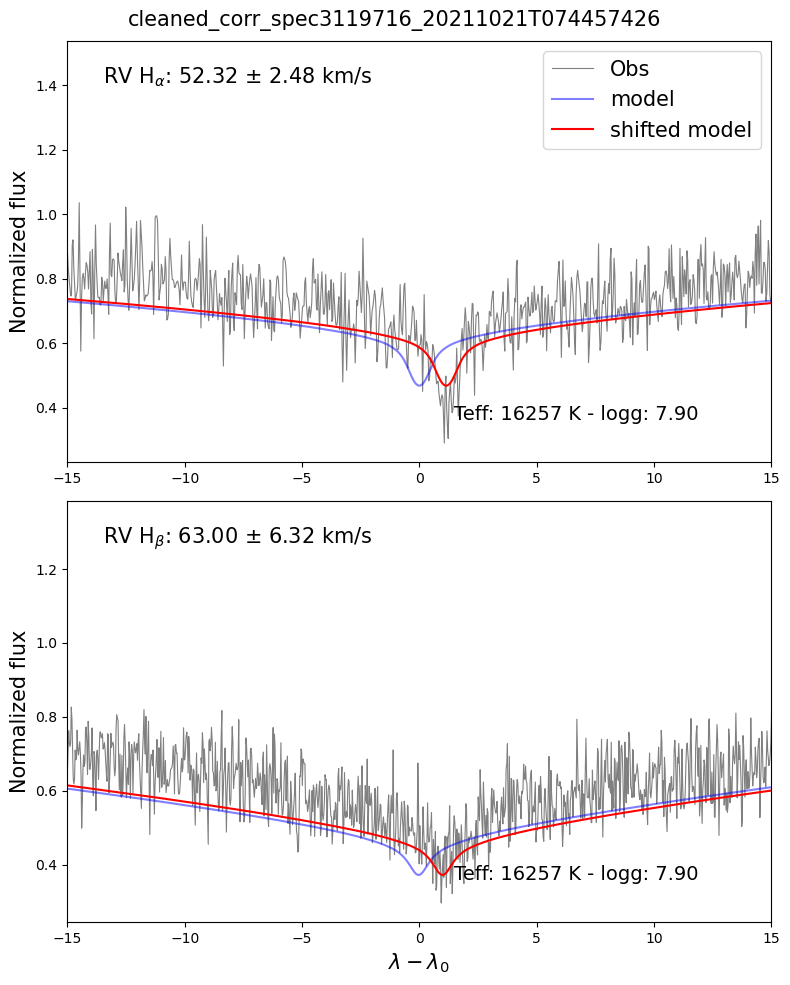

-------------------------------
52.0 64.0
cleaned_corr_spec3119716_20211021T074457426 Ha 52.03999999999936 2.4552526628552513
wave 0       6400.020421
1       6400.053466
2       6400.086511
3       6400.119556
4       6400.152601
           ...     
7255    6639.862157
7256    6639.895202
7257    6639.928247
7258    6639.961292
7259    6639.994337
Name: wave, Length: 7260, dtype: float64
cleaned_corr_spec3119716_20211021T074457426 Hb 64.27999999999892 6.063151628256053
wave 0       4790.020506
1       4790.048173
2       4790.075840
3       4790.103507
4       4790.131173
           ...     
9392    5049.866247
9393    5049.893914
9394    5049.921580
9395    5049.949247
9396    5049.976914
Name: wave, Length: 9397, dtype: float64


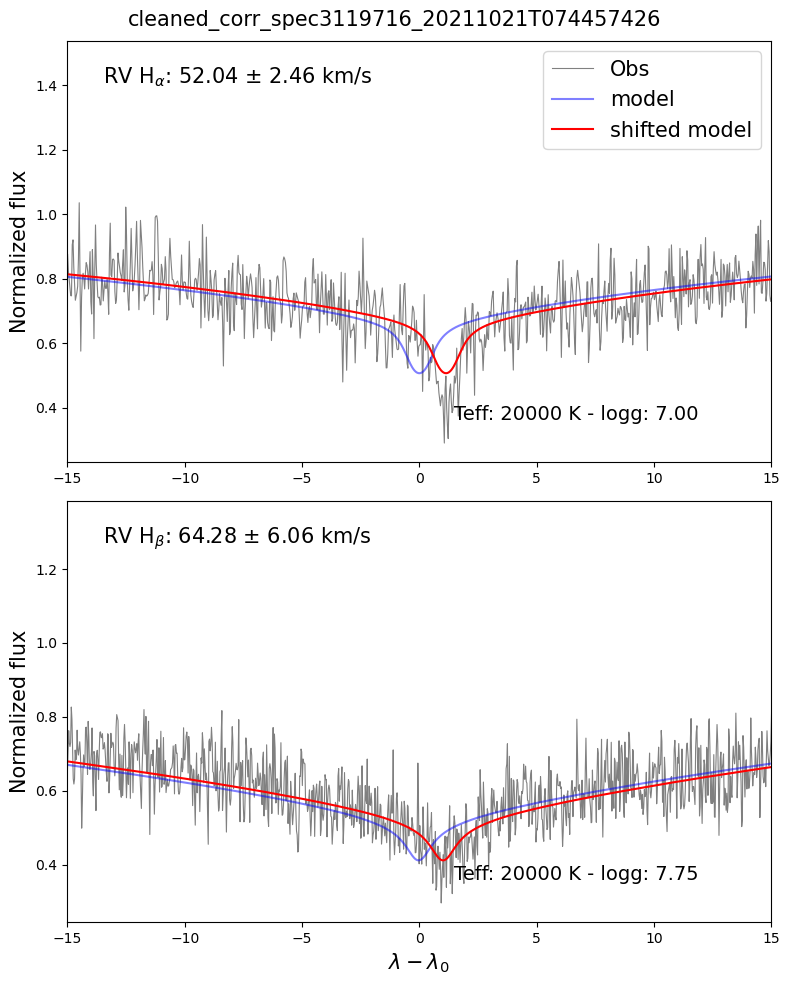

-------------------------------
Datos de ajuste (GF y MJ) guardados para: cleaned_corr_spec3119716_20211021T074457426
44.0 43.0
cleaned_corr_spec4498898_20251115T004618959 Ha 43.23999999999959 1.9159250191957538
wave 0       6400.0034
1       6400.0386
2       6400.0737
3       6400.1094
4       6400.1445
          ...    
6777    6639.8237
6778    6639.8590
6779    6639.8945
6780    6639.9297
6781    6639.9650
Name: wave, Length: 6782, dtype: float64
cleaned_corr_spec4498898_20251115T004618959 Hb 42.95999999999936 3.6404856352331523
wave 0       4790.0170
1       4790.0464
2       4790.0757
3       4790.1055
4       4790.1350
          ...    
8846    5049.8735
8847    5049.9033
8848    5049.9326
8849    5049.9620
8850    5049.9910
Name: wave, Length: 8851, dtype: float64


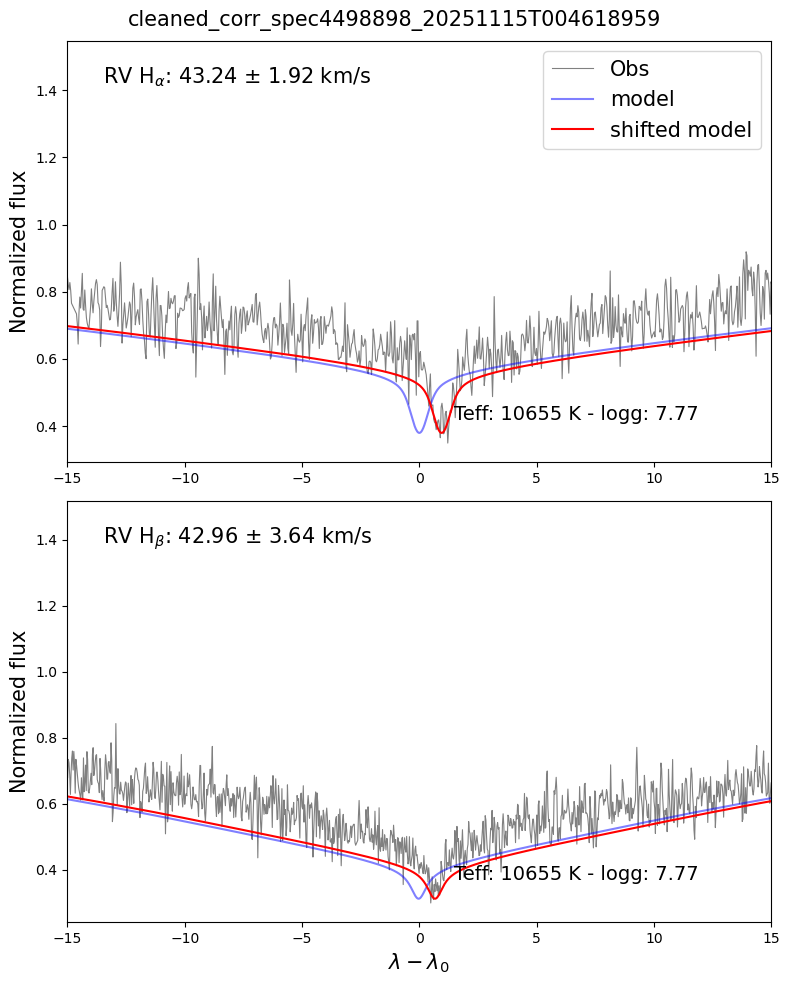

-------------------------------
44.0 43.0
cleaned_corr_spec4498898_20251115T004618959 Ha 43.919999999999575 1.9276808648080097
wave 0       6400.0034
1       6400.0386
2       6400.0737
3       6400.1094
4       6400.1445
          ...    
6777    6639.8237
6778    6639.8590
6779    6639.8945
6780    6639.9297
6781    6639.9650
Name: wave, Length: 6782, dtype: float64
cleaned_corr_spec4498898_20251115T004618959 Hb 42.91999999999936 3.5162599650344903
wave 0       4790.0170
1       4790.0464
2       4790.0757
3       4790.1055
4       4790.1350
          ...    
8846    5049.8735
8847    5049.9033
8848    5049.9326
8849    5049.9620
8850    5049.9910
Name: wave, Length: 8851, dtype: float64


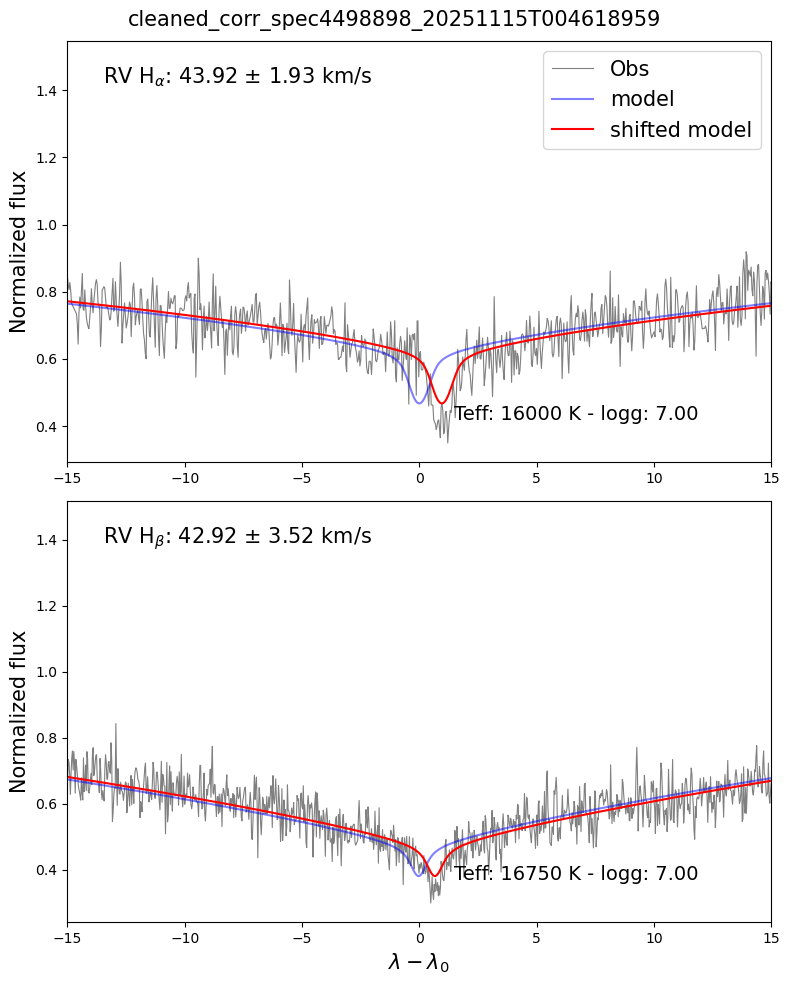

-------------------------------
Datos de ajuste (GF y MJ) guardados para: cleaned_corr_spec4498898_20251115T004618959
55.0 129.0
cleaned_corr_spec4498799_20260312T064143284 Ha 54.479999999999585 1.9453104482441541
wave 0       6400.0240
1       6400.0590
2       6400.0940
3       6400.1294
4       6400.1640
          ...    
6839    6639.8450
6840    6639.8804
6841    6639.9150
6842    6639.9500
6843    6639.9854
Name: wave, Length: 6844, dtype: float64
cleaned_corr_spec4498799_20260312T064143284 Hb 69.0 6.9869686756230545
wave 0       4790.0040
1       4790.0330
2       4790.0625
3       4790.0920
4       4790.1216
          ...    
8856    5049.8750
8857    5049.9043
8858    5049.9336
8859    5049.9630
8860    5049.9920
Name: wave, Length: 8861, dtype: float64


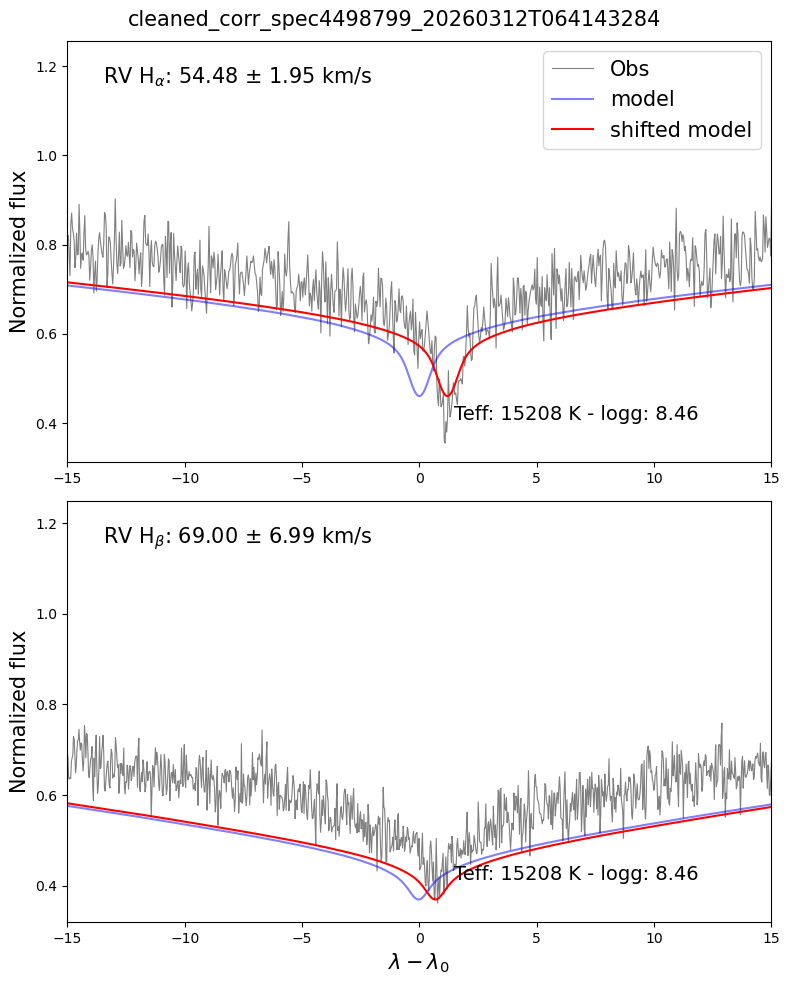

-------------------------------
55.0 129.0
cleaned_corr_spec4498799_20260312T064143284 Ha 54.999999999999574 1.750330275043407
wave 0       6400.0240
1       6400.0590
2       6400.0940
3       6400.1294
4       6400.1640
          ...    
6839    6639.8450
6840    6639.8804
6841    6639.9150
6842    6639.9500
6843    6639.9854
Name: wave, Length: 6844, dtype: float64
cleaned_corr_spec4498799_20260312T064143284 Hb 69.0 6.698919310210956
wave 0       4790.0040
1       4790.0330
2       4790.0625
3       4790.0920
4       4790.1216
          ...    
8856    5049.8750
8857    5049.9043
8858    5049.9336
8859    5049.9630
8860    5049.9920
Name: wave, Length: 8861, dtype: float64


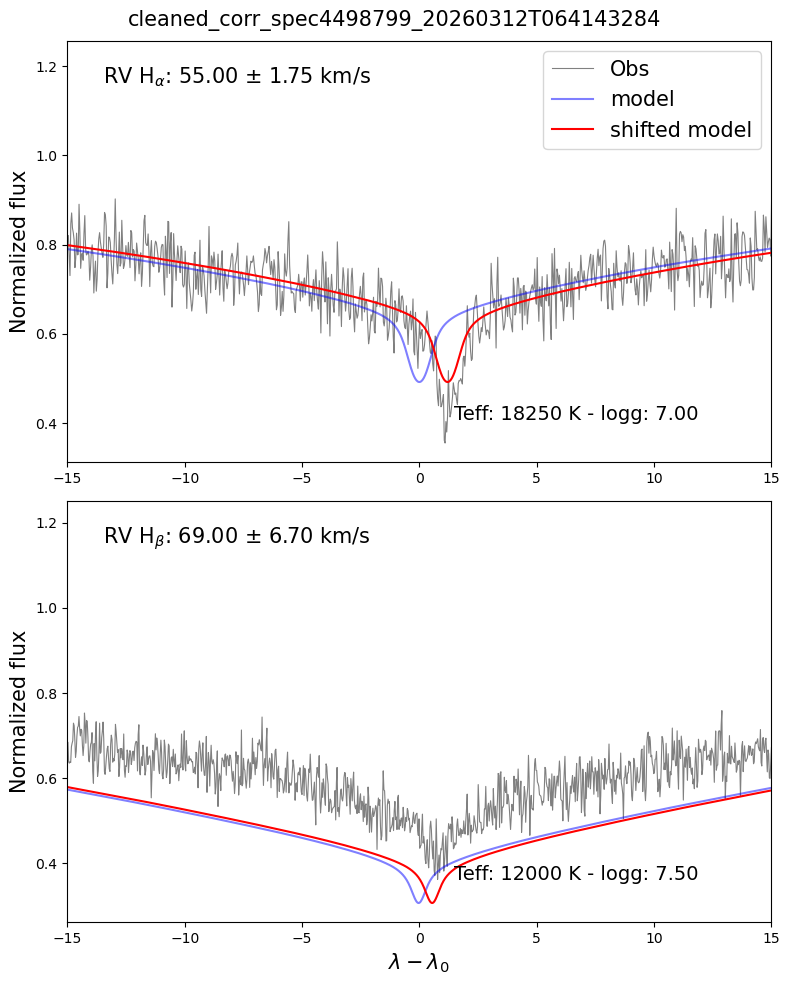

-------------------------------
Datos de ajuste (GF y MJ) guardados para: cleaned_corr_spec4498799_20260312T064143284
34.0 28.0
cleaned_corr_spec3110806_20220117T041533928 Ha 34.28000000000004 3.025863580934075
wave 0       6400.003231
1       6400.036296
2       6400.069360
3       6400.102425
4       6400.135489
           ...     
7254    6639.853322
7255    6639.886387
7256    6639.919451
7257    6639.952516
7258    6639.985580
Name: wave, Length: 7259, dtype: float64
cleaned_corr_spec3110806_20220117T041533928 Hb 28.999999999999126 4.22272923585517
wave 0       4790.001244
1       4790.028965
2       4790.056686
3       4790.084407
4       4790.112128
           ...     
9374    5049.884467
9375    5049.912188
9376    5049.939909
9377    5049.967630
9378    5049.995351
Name: wave, Length: 9379, dtype: float64


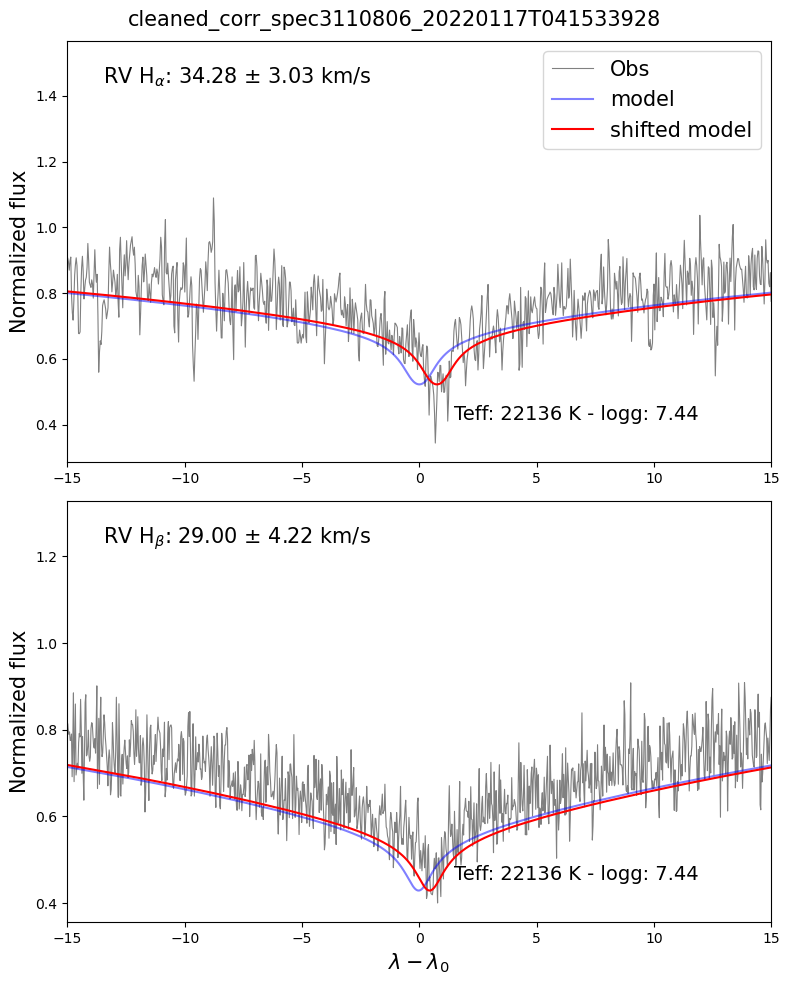

-------------------------------
34.0 28.0
cleaned_corr_spec3110806_20220117T041533928 Ha 33.92000000000004 3.446452234919352
wave 0       6400.003231
1       6400.036296
2       6400.069360
3       6400.102425
4       6400.135489
           ...     
7254    6639.853322
7255    6639.886387
7256    6639.919451
7257    6639.952516
7258    6639.985580
Name: wave, Length: 7259, dtype: float64
cleaned_corr_spec3110806_20220117T041533928 Hb 28.039999999999146 4.558332706899281
wave 0       4790.001244
1       4790.028965
2       4790.056686
3       4790.084407
4       4790.112128
           ...     
9374    5049.884467
9375    5049.912188
9376    5049.939909
9377    5049.967630
9378    5049.995351
Name: wave, Length: 9379, dtype: float64


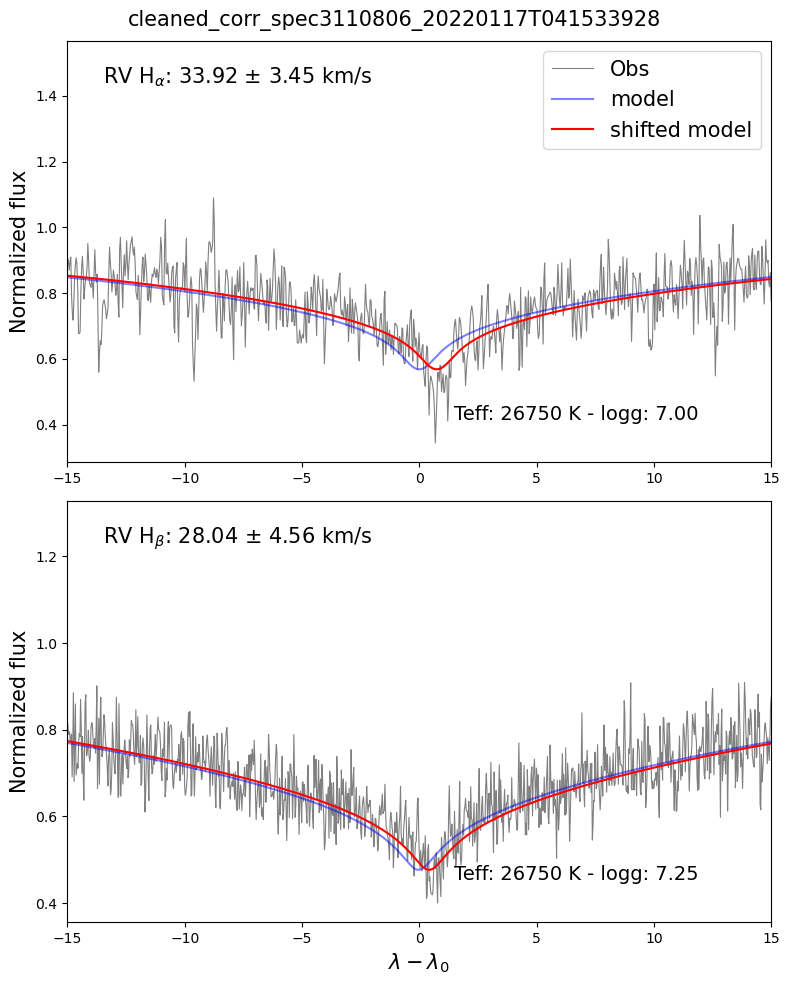

-------------------------------
Datos de ajuste (GF y MJ) guardados para: cleaned_corr_spec3110806_20220117T041533928
-40.0 -34.0
cleaned_corr_spec4498529_20260411T060427246 Ha -40.040000000000425 2.111602438278506
wave 0       6400.0030
1       6400.0380
2       6400.0730
3       6400.1084
4       6400.1436
          ...    
6826    6639.8374
6827    6639.8726
6828    6639.9077
6829    6639.9430
6830    6639.9780
Name: wave, Length: 6831, dtype: float64
cleaned_corr_spec4498529_20260411T060427246 Hb -34.32000000000063 5.492847790055542
wave 0       4790.0140
1       4790.0435
2       4790.0723
3       4790.1016
4       4790.1310
          ...    
8921    5049.8560
8922    5049.8850
8923    5049.9140
8924    5049.9434
8925    5049.9720
Name: wave, Length: 8926, dtype: float64


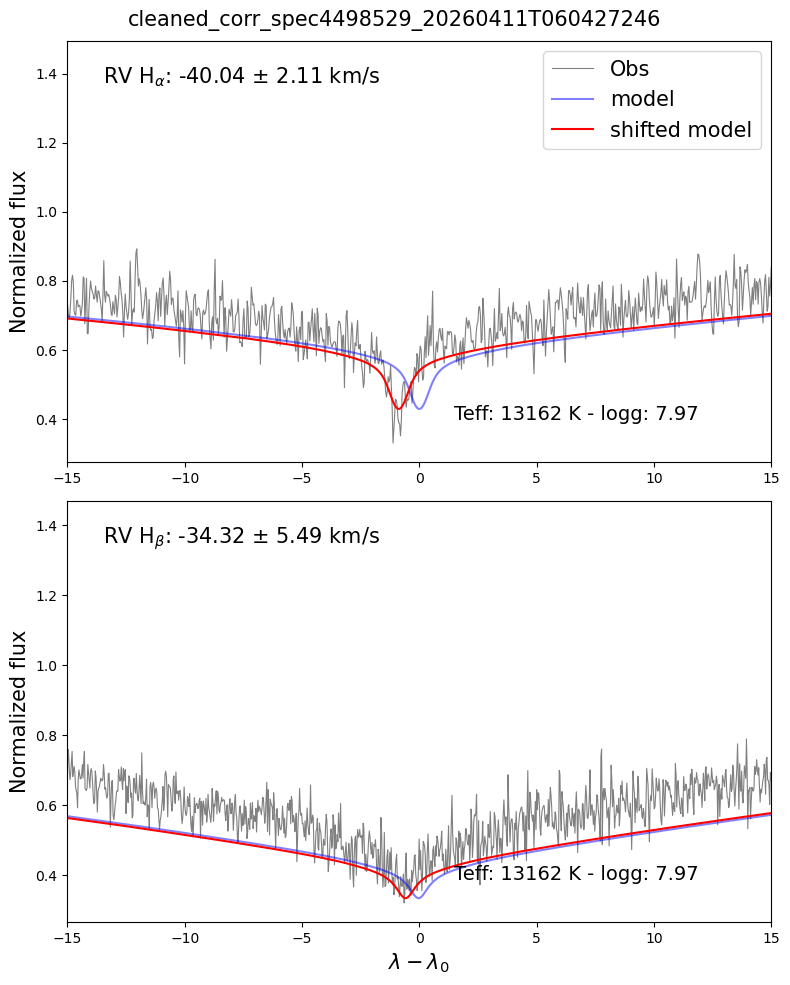

-------------------------------
-40.0 -34.0
cleaned_corr_spec4498529_20260411T060427246 Ha -39.84000000000043 1.9826125782888853
wave 0       6400.0030
1       6400.0380
2       6400.0730
3       6400.1084
4       6400.1436
          ...    
6826    6639.8374
6827    6639.8726
6828    6639.9077
6829    6639.9430
6830    6639.9780
Name: wave, Length: 6831, dtype: float64
cleaned_corr_spec4498529_20260411T060427246 Hb -33.40000000000065 4.661526173350239
wave 0       4790.0140
1       4790.0435
2       4790.0723
3       4790.1016
4       4790.1310
          ...    
8921    5049.8560
8922    5049.8850
8923    5049.9140
8924    5049.9434
8925    5049.9720
Name: wave, Length: 8926, dtype: float64


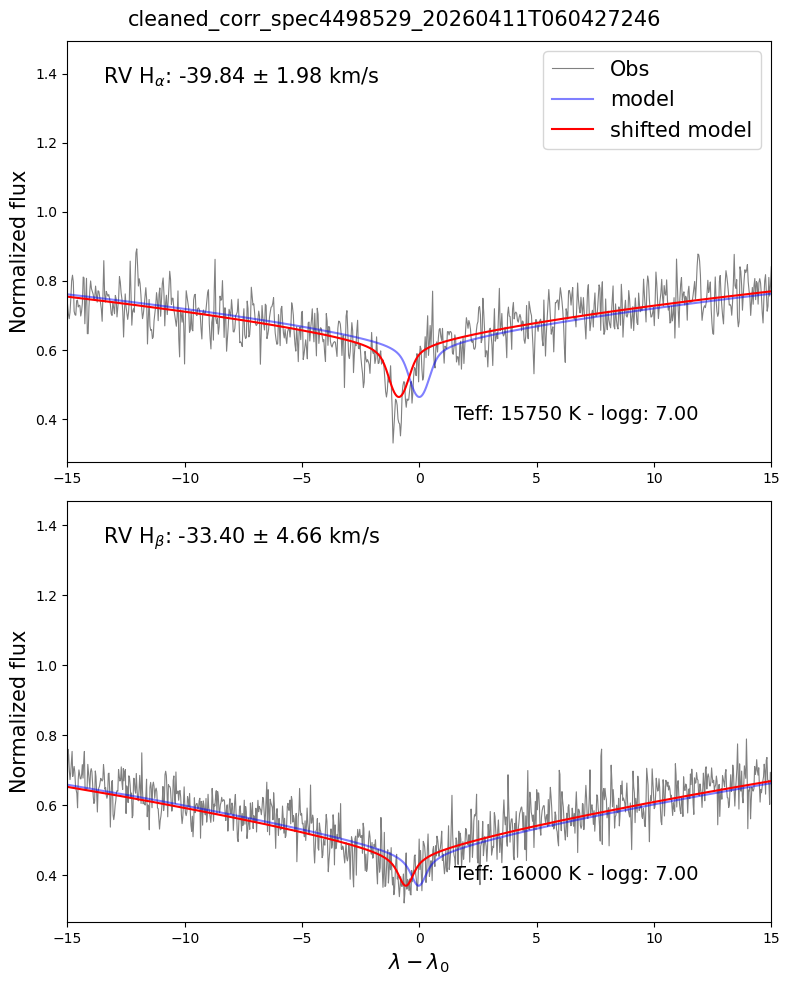

-------------------------------
Datos de ajuste (GF y MJ) guardados para: cleaned_corr_spec4498529_20260411T060427246
77.0 70.0
cleaned_corr_spec4498301_20260117T023704886 Ha 75.75999999999897 2.3669291288238687
wave 0       6400.021226
1       6400.056868
2       6400.092022
3       6400.127176
4       6400.162818
           ...     
6787    6639.826479
6788    6639.862121
6789    6639.897275
6790    6639.932429
6791    6639.968071
Name: wave, Length: 6792, dtype: float64
cleaned_corr_spec4498301_20260117T023704886 Hb 67.4399999999992 3.5357790148153057
wave 0       4790.017077
1       4790.046372
2       4790.075667
3       4790.104961
4       4790.134256
           ...     
8890    5049.862493
8891    5049.891788
8892    5049.921083
8893    5049.949889
8894    5049.979184
Name: wave, Length: 8895, dtype: float64


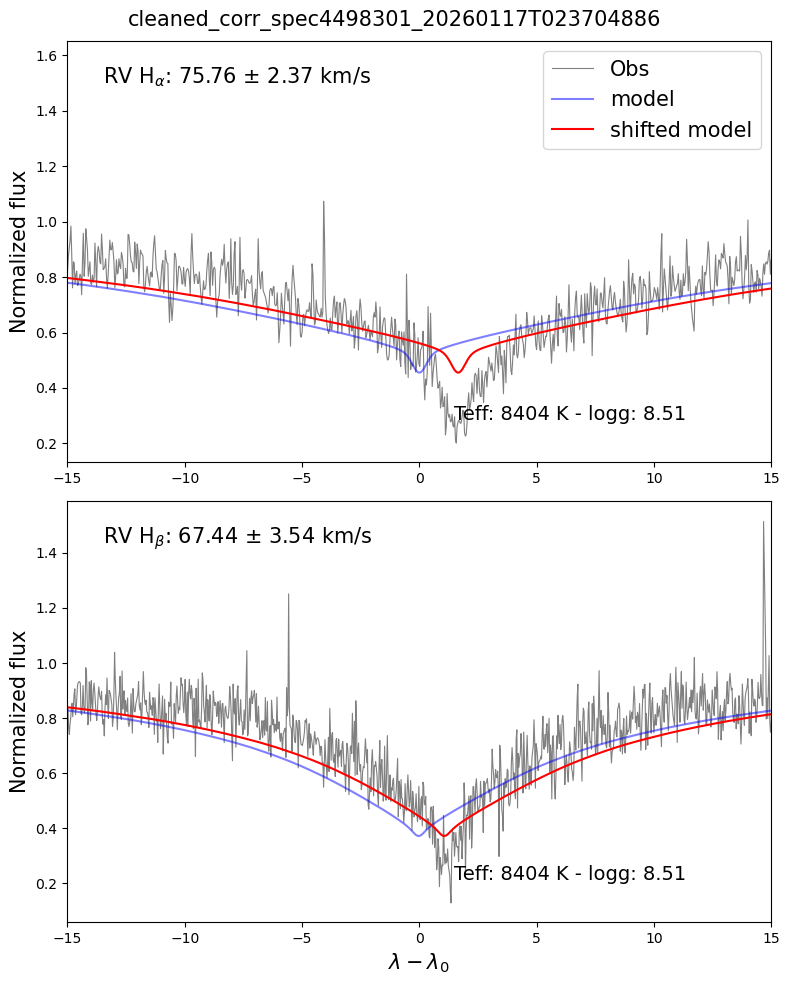

-------------------------------
77.0 70.0
cleaned_corr_spec4498301_20260117T023704886 Ha 77.59999999999891 2.3682181626907677
wave 0       6400.021226
1       6400.056868
2       6400.092022
3       6400.127176
4       6400.162818
           ...     
6787    6639.826479
6788    6639.862121
6789    6639.897275
6790    6639.932429
6791    6639.968071
Name: wave, Length: 6792, dtype: float64
cleaned_corr_spec4498301_20260117T023704886 Hb 70.35999999999913 2.9283516790796074
wave 0       4790.017077
1       4790.046372
2       4790.075667
3       4790.104961
4       4790.134256
           ...     
8890    5049.862493
8891    5049.891788
8892    5049.921083
8893    5049.949889
8894    5049.979184
Name: wave, Length: 8895, dtype: float64


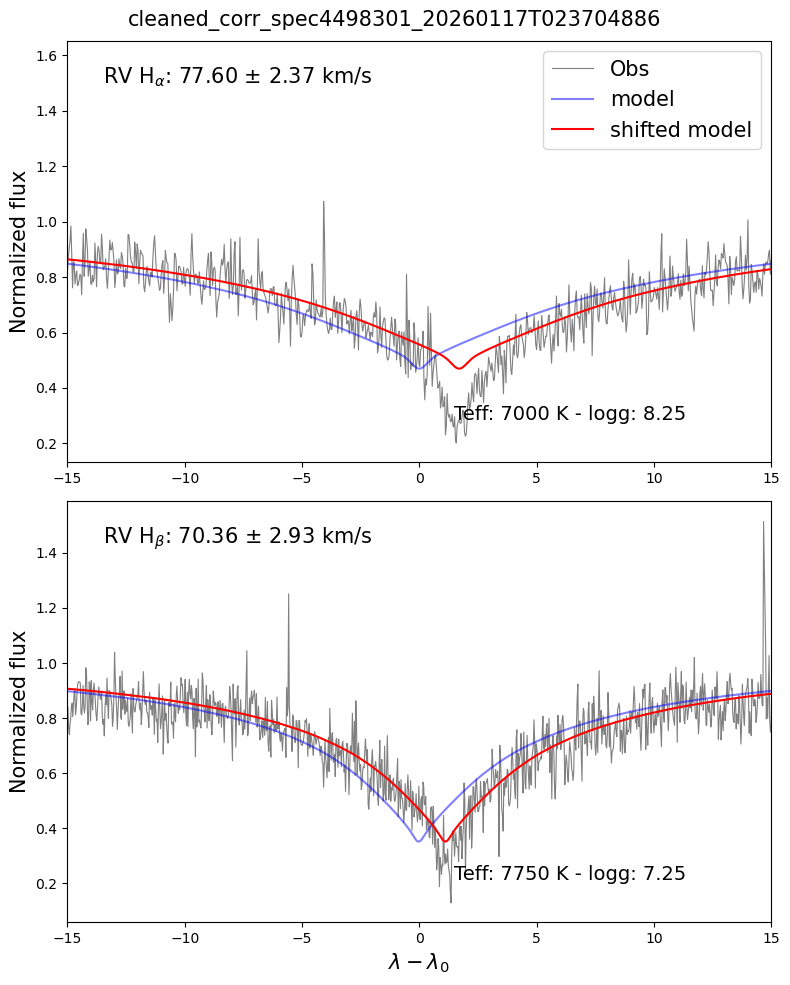

-------------------------------
Datos de ajuste (GF y MJ) guardados para: cleaned_corr_spec4498301_20260117T023704886
47.0 4.0
Error en ajuste GF para cleaned_corr_spec4498551_20251025T001253572: unsupported operand type(s) for *: 'NoneType' and 'float'
47.0 4.0
cleaned_corr_spec4498551_20251025T001253572 Ha 45.479999999998114 10.023896709495409
wave 0       6400.0260
1       6400.0610
2       6400.0960
3       6400.1320
4       6400.1670
          ...    
6812    6639.8400
6813    6639.8750
6814    6639.9100
6815    6639.9453
6816    6639.9805
Name: wave, Length: 6817, dtype: float64
cleaned_corr_spec4498551_20251025T001253572 Hb 3.8399999999989376 5.651735332313649
wave 0       4790.0100
1       4790.0390
2       4790.0684
3       4790.0977
4       4790.1265
          ...    
8881    5049.8550
8882    5049.8843
8883    5049.9136
8884    5049.9430
8885    5049.9720
Name: wave, Length: 8886, dtype: float64


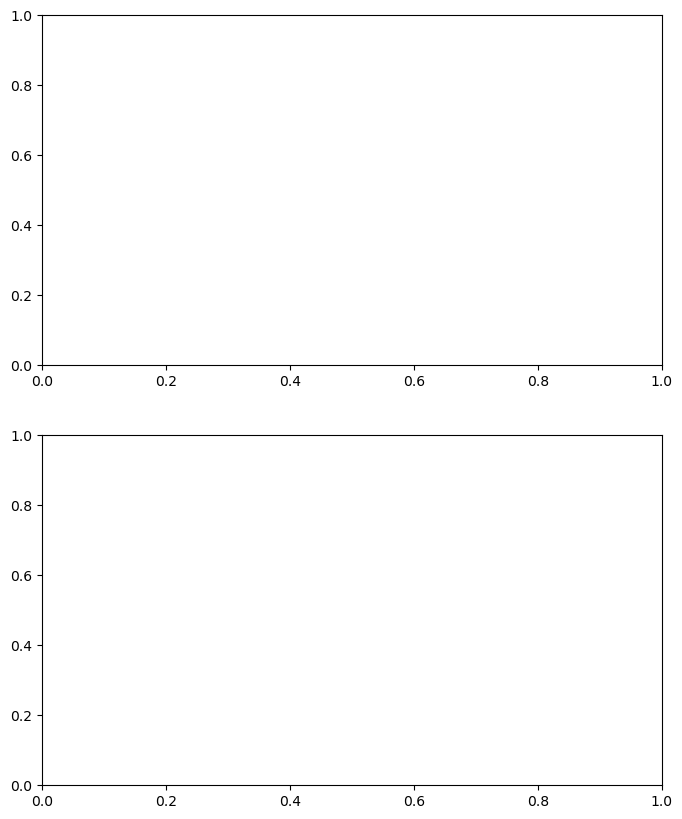

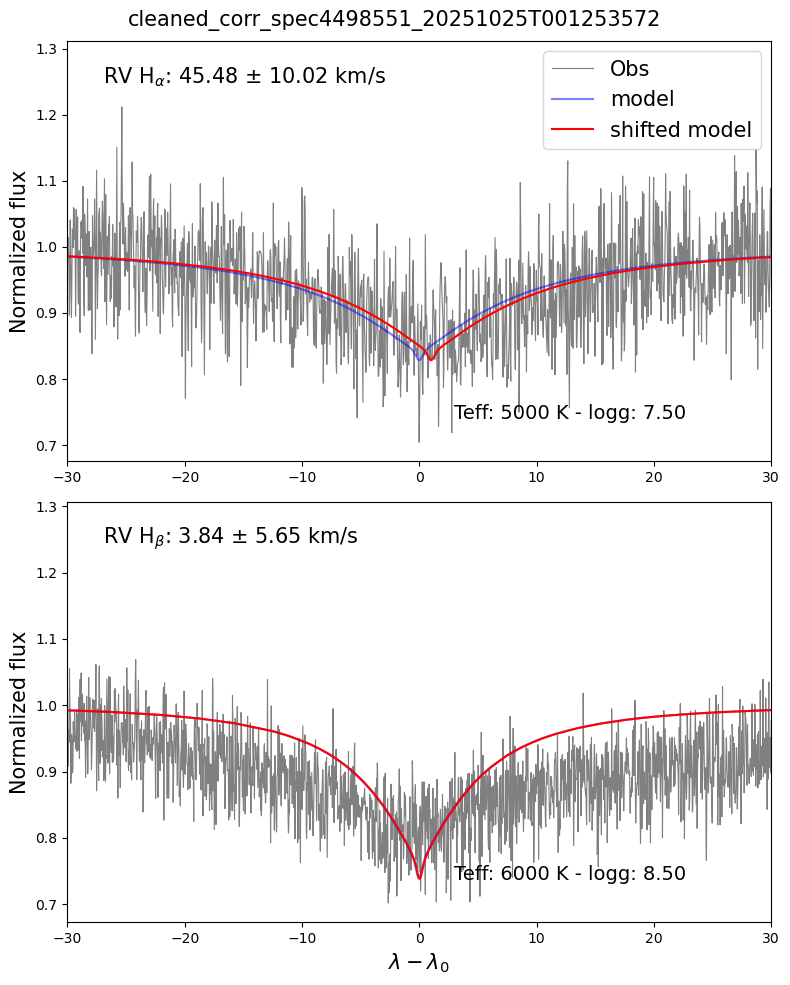

-------------------------------
Datos de ajuste (GF y MJ) guardados para: cleaned_corr_spec4498551_20251025T001253572
35.0 33.0
cleaned_corr_spec4498517_20260318T090835813 Ha 35.44000000000003 2.290725487567462
wave 0       6400.0150
1       6400.0503
2       6400.0850
3       6400.1200
4       6400.1553
          ...    
6862    6639.8296
6863    6639.8643
6864    6639.8994
6865    6639.9340
6866    6639.9690
Name: wave, Length: 6867, dtype: float64
cleaned_corr_spec4498517_20260318T090835813 Hb 31.240000000000038 2.796068033335819
wave 0       4790.0050
1       4790.0340
2       4790.0635
3       4790.0930
4       4790.1216
          ...    
8889    5049.8604
8890    5049.8896
8891    5049.9190
8892    5049.9480
8893    5049.9770
Name: wave, Length: 8894, dtype: float64


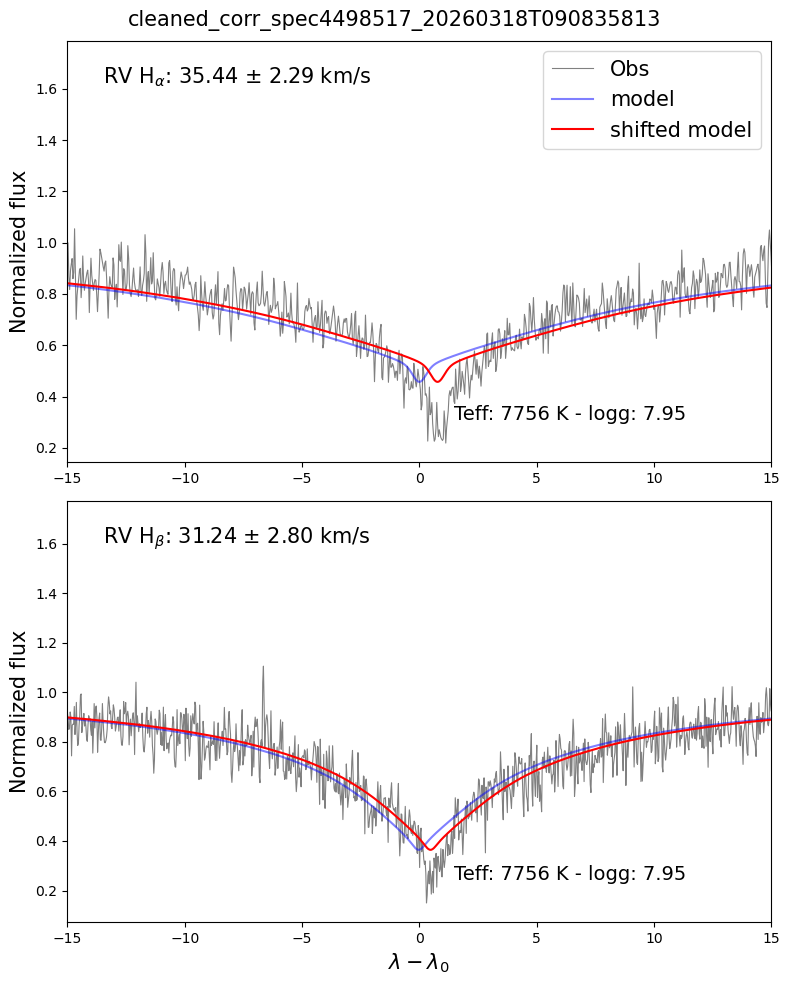

-------------------------------
35.0 33.0
cleaned_corr_spec4498517_20260318T090835813 Ha 35.44000000000003 2.409930137698789
wave 0       6400.0150
1       6400.0503
2       6400.0850
3       6400.1200
4       6400.1553
          ...    
6862    6639.8296
6863    6639.8643
6864    6639.8994
6865    6639.9340
6866    6639.9690
Name: wave, Length: 6867, dtype: float64
cleaned_corr_spec4498517_20260318T090835813 Hb 32.720000000000034 2.7057945013401583
wave 0       4790.0050
1       4790.0340
2       4790.0635
3       4790.0930
4       4790.1216
          ...    
8889    5049.8604
8890    5049.8896
8891    5049.9190
8892    5049.9480
8893    5049.9770
Name: wave, Length: 8894, dtype: float64


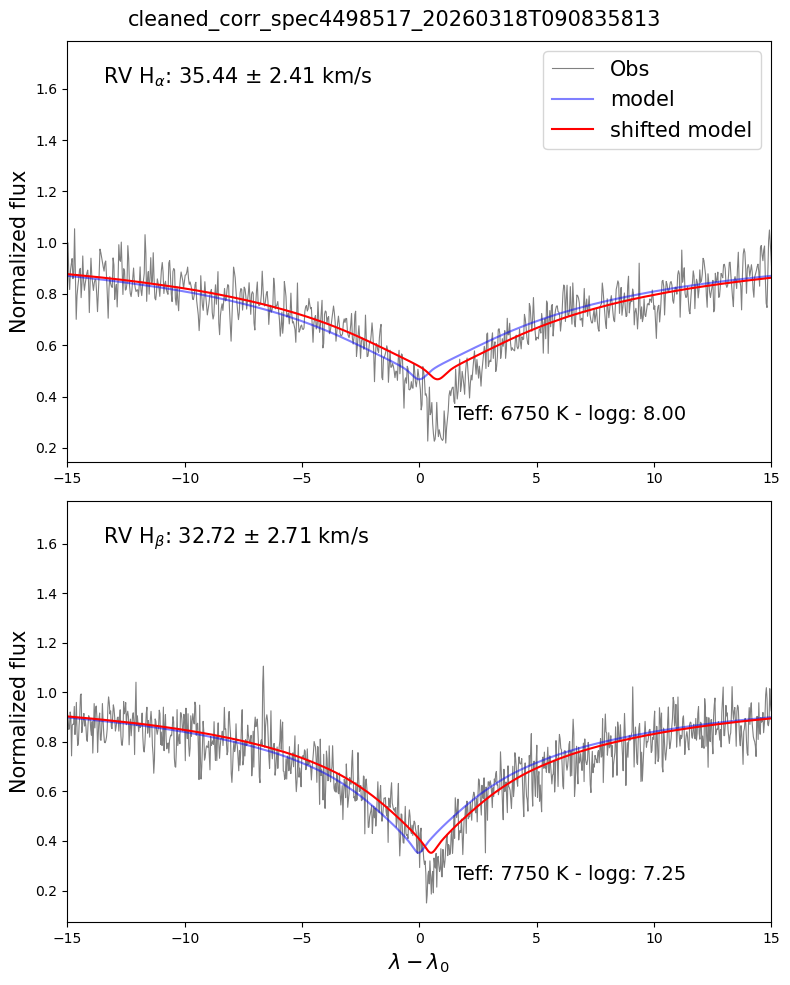

-------------------------------
Datos de ajuste (GF y MJ) guardados para: cleaned_corr_spec4498517_20260318T090835813
32.0 41.0
cleaned_corr_spec4498436_20251115T042515747 Ha 32.55999999999956 2.0789354286387183
wave 0       6400.011575
1       6400.047219
2       6400.082376
3       6400.117533
4       6400.153178
           ...     
6777    6639.845405
6778    6639.881050
6779    6639.916207
6780    6639.951363
6781    6639.987008
Name: wave, Length: 6782, dtype: float64
cleaned_corr_spec4498436_20251115T042515747 Hb 40.15999999999938 5.487870557018618
wave 0       4790.023702
1       4790.052999
2       4790.082296
3       4790.111594
4       4790.140891
           ...     
8845    5049.865577
8846    5049.894874
8847    5049.924171
8848    5049.953468
8849    5049.982766
Name: wave, Length: 8850, dtype: float64


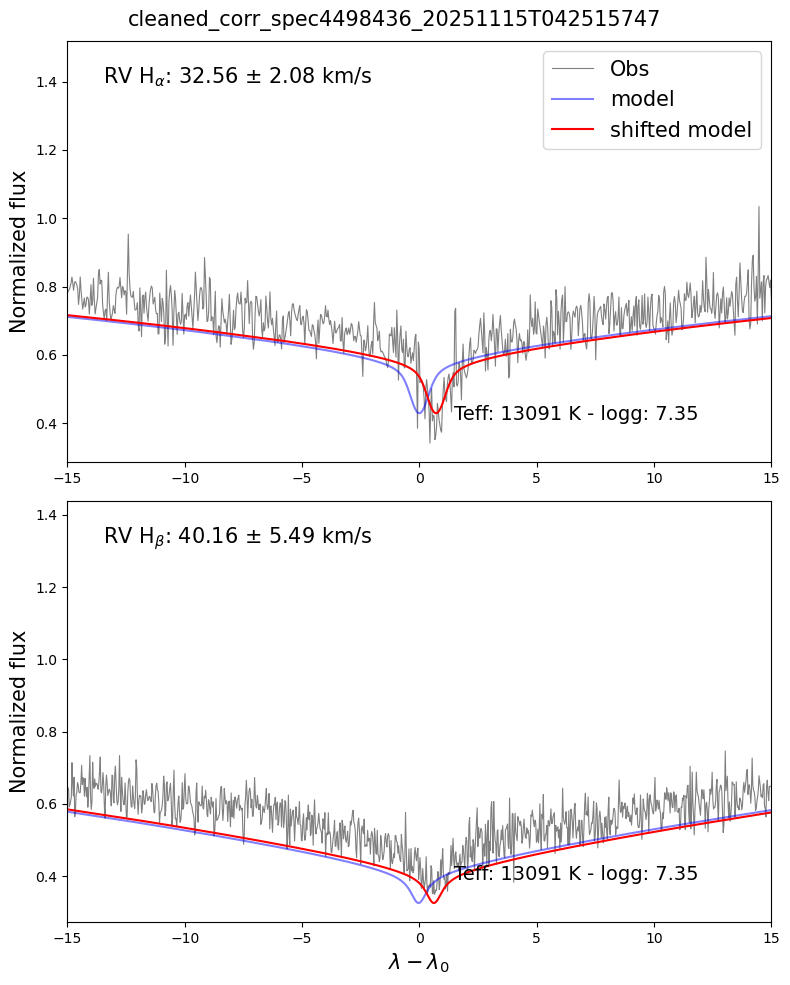

-------------------------------
32.0 41.0
cleaned_corr_spec4498436_20251115T042515747 Ha 32.51999999999956 2.0540285378768925
wave 0       6400.011575
1       6400.047219
2       6400.082376
3       6400.117533
4       6400.153178
           ...     
6777    6639.845405
6778    6639.881050
6779    6639.916207
6780    6639.951363
6781    6639.987008
Name: wave, Length: 6782, dtype: float64
cleaned_corr_spec4498436_20251115T042515747 Hb 40.87999999999936 5.187002930384356
wave 0       4790.023702
1       4790.052999
2       4790.082296
3       4790.111594
4       4790.140891
           ...     
8845    5049.865577
8846    5049.894874
8847    5049.924171
8848    5049.953468
8849    5049.982766
Name: wave, Length: 8850, dtype: float64


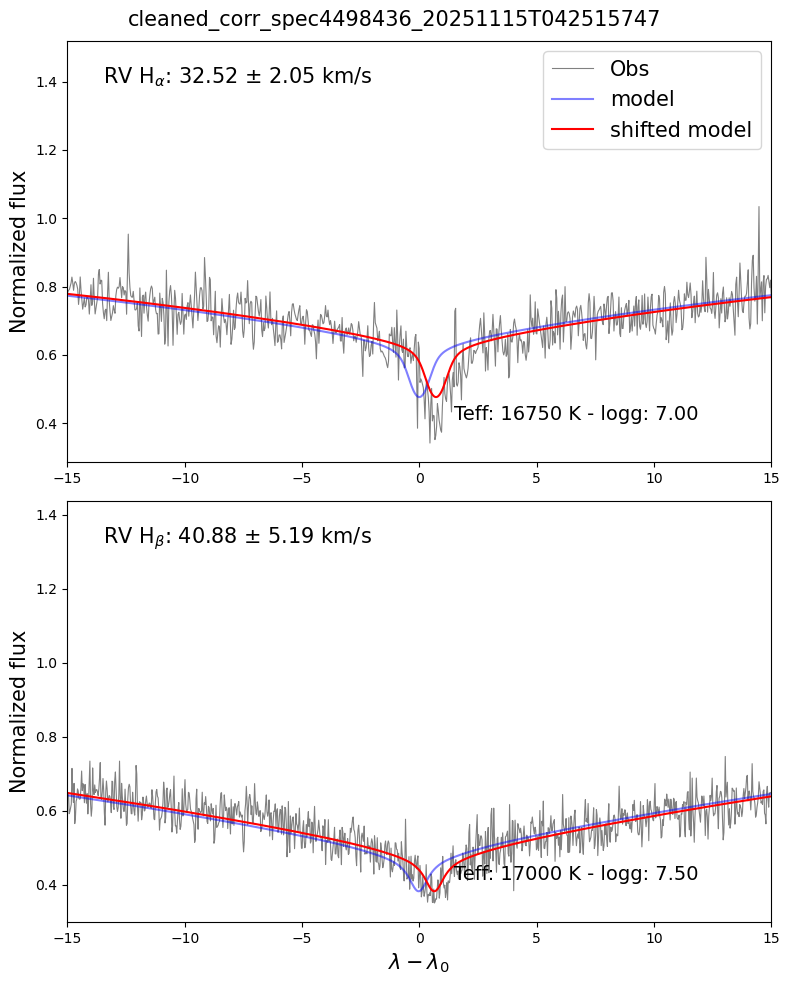

-------------------------------
Datos de ajuste (GF y MJ) guardados para: cleaned_corr_spec4498436_20251115T042515747
-49.0 -27.0
cleaned_corr_spec4498834_20251117T021717638 Ha -48.639999999995254 3.3092313707730048
wave 0       6400.0160
1       6400.0513
2       6400.0870
3       6400.1220
4       6400.1570
          ...    
6788    6639.8330
6789    6639.8680
6790    6639.9040
6791    6639.9390
6792    6639.9740
Name: wave, Length: 6793, dtype: float64
cleaned_corr_spec4498834_20251117T021717638 Hb -28.399999999992403 5.984057423496833
wave 0       4790.0060
1       4790.0356
2       4790.0650
3       4790.0940
4       4790.1235
          ...    
8846    5049.8594
8847    5049.8887
8848    5049.9180
8849    5049.9473
8850    5049.9766
Name: wave, Length: 8851, dtype: float64


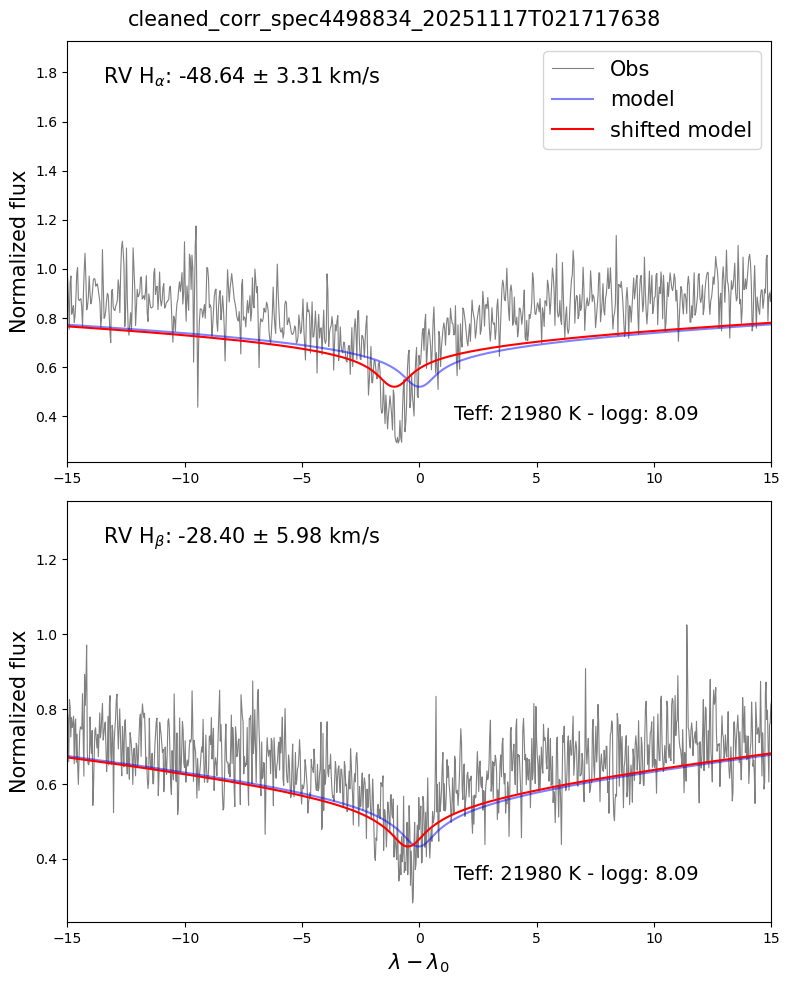

-------------------------------
-49.0 -27.0
cleaned_corr_spec4498834_20251117T021717638 Ha -48.67999999999526 2.5133557512232194
wave 0       6400.0160
1       6400.0513
2       6400.0870
3       6400.1220
4       6400.1570
          ...    
6788    6639.8330
6789    6639.8680
6790    6639.9040
6791    6639.9390
6792    6639.9740
Name: wave, Length: 6793, dtype: float64
cleaned_corr_spec4498834_20251117T021717638 Hb -26.959999999992178 5.247335632097145
wave 0       4790.0060
1       4790.0356
2       4790.0650
3       4790.0940
4       4790.1235
          ...    
8846    5049.8594
8847    5049.8887
8848    5049.9180
8849    5049.9473
8850    5049.9766
Name: wave, Length: 8851, dtype: float64


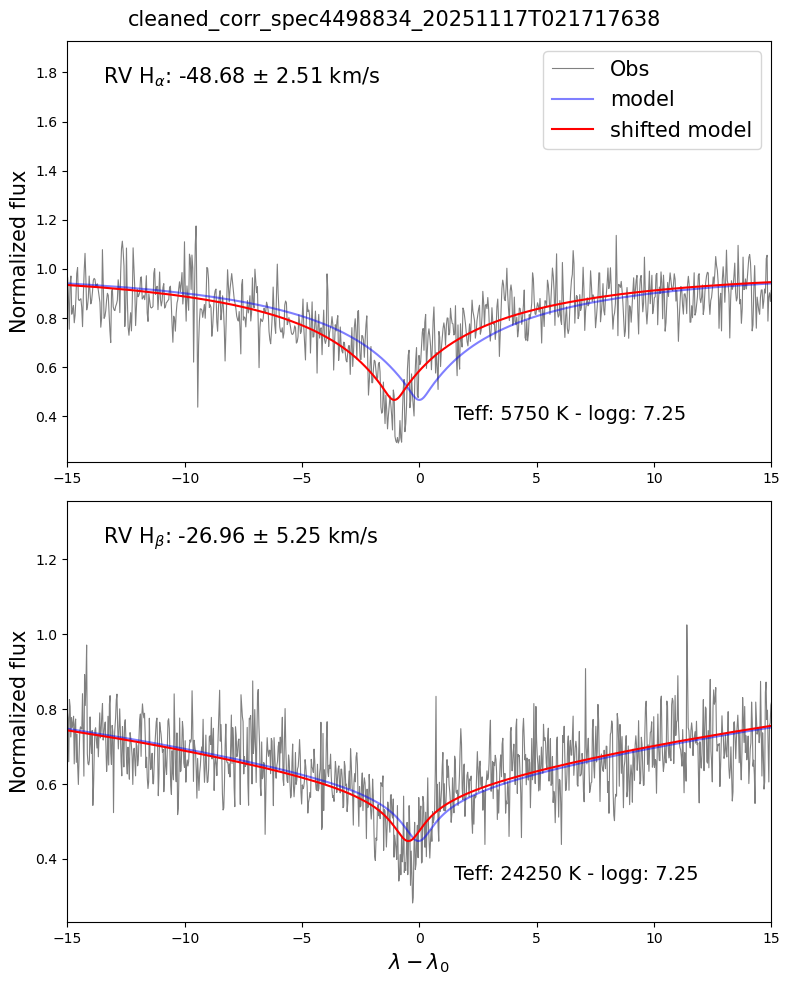

-------------------------------
Datos de ajuste (GF y MJ) guardados para: cleaned_corr_spec4498834_20251117T021717638
58.0 60.0
cleaned_corr_spec3119716_20211021T080906487 Ha 57.51999999999937 1.957572731914925
wave 0       6400.019887
1       6400.052932
2       6400.085977
3       6400.119022
4       6400.152067
           ...     
7257    6639.861603
7258    6639.894648
7259    6639.927693
7260    6639.960738
7261    6639.993783
Name: wave, Length: 7262, dtype: float64
cleaned_corr_spec3119716_20211021T080906487 Hb 59.95999999999915 5.006951767116994
wave 0       4790.020107
1       4790.047773
2       4790.075440
3       4790.103107
4       4790.130774
           ...     
9392    5049.865826
9393    5049.893492
9394    5049.921159
9395    5049.948826
9396    5049.976492
Name: wave, Length: 9397, dtype: float64


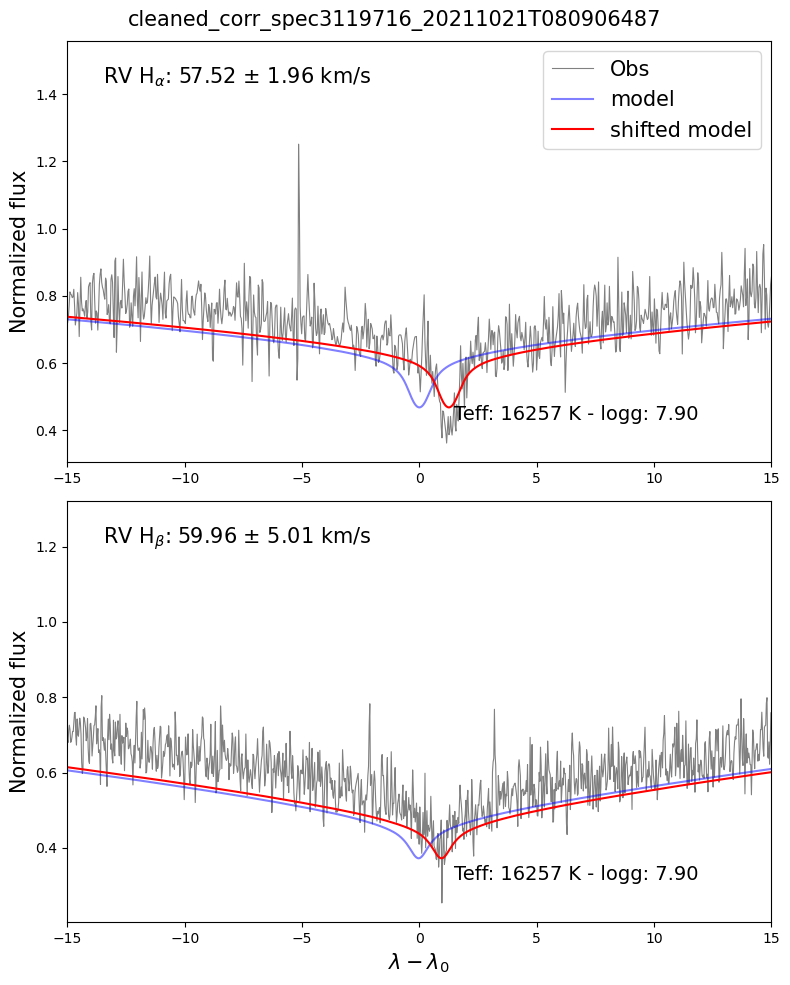

-------------------------------
58.0 60.0
cleaned_corr_spec3119716_20211021T080906487 Ha 57.63999999999937 1.9115253067537081
wave 0       6400.019887
1       6400.052932
2       6400.085977
3       6400.119022
4       6400.152067
           ...     
7257    6639.861603
7258    6639.894648
7259    6639.927693
7260    6639.960738
7261    6639.993783
Name: wave, Length: 7262, dtype: float64
cleaned_corr_spec3119716_20211021T080906487 Hb 60.79999999999913 4.56917040446217
wave 0       4790.020107
1       4790.047773
2       4790.075440
3       4790.103107
4       4790.130774
           ...     
9392    5049.865826
9393    5049.893492
9394    5049.921159
9395    5049.948826
9396    5049.976492
Name: wave, Length: 9397, dtype: float64


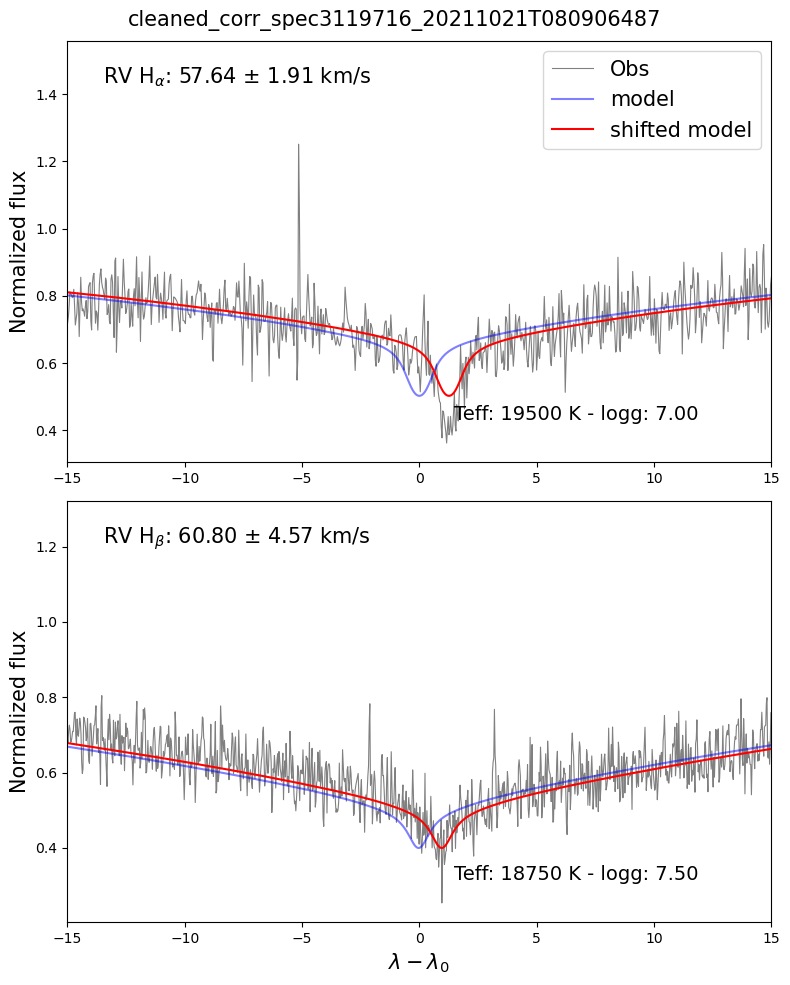

-------------------------------
Datos de ajuste (GF y MJ) guardados para: cleaned_corr_spec3119716_20211021T080906487
33.0 30.0
cleaned_corr_spec4498344_20260121T054555423 Ha 33.51999999999956 1.6250366496054363
wave 0       6400.0195
1       6400.0547
2       6400.0903
3       6400.1255
4       6400.1606
          ...    
6783    6639.8380
6784    6639.8735
6785    6639.9087
6786    6639.9443
6787    6639.9795
Name: wave, Length: 6788, dtype: float64
cleaned_corr_spec4498344_20260121T054555423 Hb 30.28 4.6479335595127935
wave 0       4790.0156
1       4790.0450
2       4790.0740
3       4790.1030
4       4790.1323
          ...    
8902    5049.8680
8903    5049.8970
8904    5049.9263
8905    5049.9556
8906    5049.9850
Name: wave, Length: 8907, dtype: float64


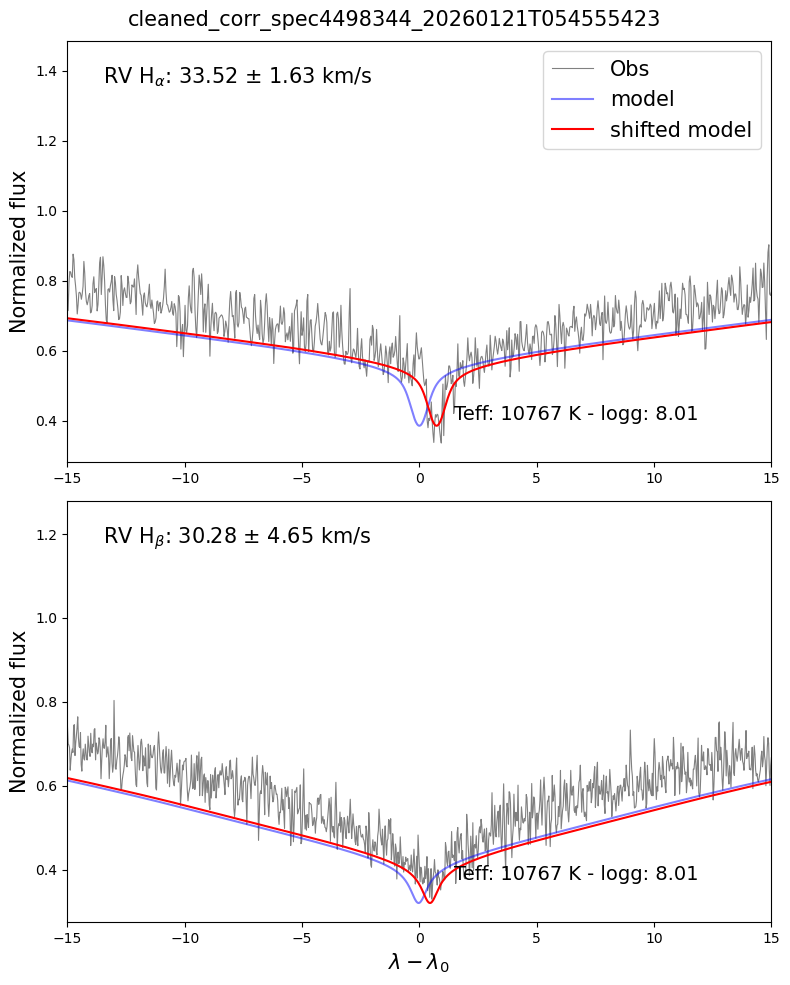

-------------------------------
33.0 30.0
cleaned_corr_spec4498344_20260121T054555423 Ha 33.07999999999957 1.4364716662178505
wave 0       6400.0195
1       6400.0547
2       6400.0903
3       6400.1255
4       6400.1606
          ...    
6783    6639.8380
6784    6639.8735
6785    6639.9087
6786    6639.9443
6787    6639.9795
Name: wave, Length: 6788, dtype: float64
cleaned_corr_spec4498344_20260121T054555423 Hb 29.6 4.28170096059476
wave 0       4790.0156
1       4790.0450
2       4790.0740
3       4790.1030
4       4790.1323
          ...    
8902    5049.8680
8903    5049.8970
8904    5049.9263
8905    5049.9556
8906    5049.9850
Name: wave, Length: 8907, dtype: float64


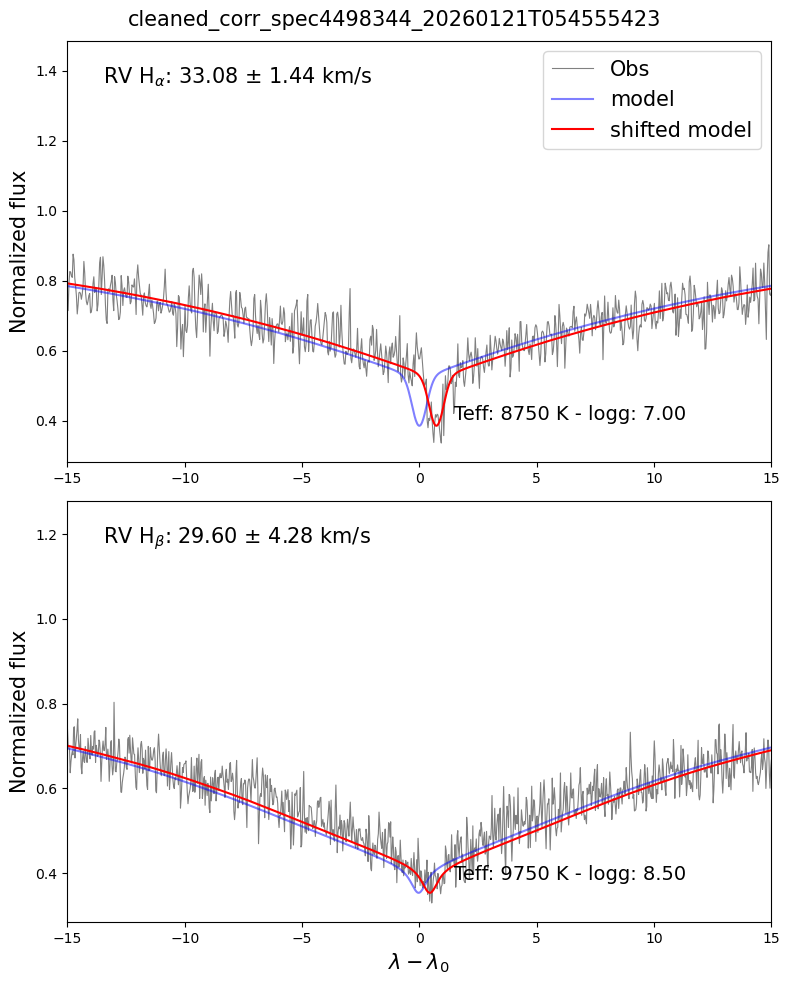

-------------------------------
Datos de ajuste (GF y MJ) guardados para: cleaned_corr_spec4498344_20260121T054555423
35.0 31.0
cleaned_corr_spec3119751_20220117T060853894 Ha 32.079999999998996 2.9130430074562894
wave 0       6400.002329
1       6400.035393
2       6400.068457
3       6400.101521
4       6400.134585
           ...     
7254    6639.848669
7255    6639.881733
7256    6639.914797
7257    6639.947861
7258    6639.980925
Name: wave, Length: 7259, dtype: float64
cleaned_corr_spec3119751_20220117T060853894 Hb 37.839999999999 8.499991025188534
wave 0       4790.009491
1       4790.037212
2       4790.064932
3       4790.092653
4       4790.120373
           ...     
9374    5049.888650
9375    5049.916370
9376    5049.944091
9377    5049.971811
9378    5049.999532
Name: wave, Length: 9379, dtype: float64


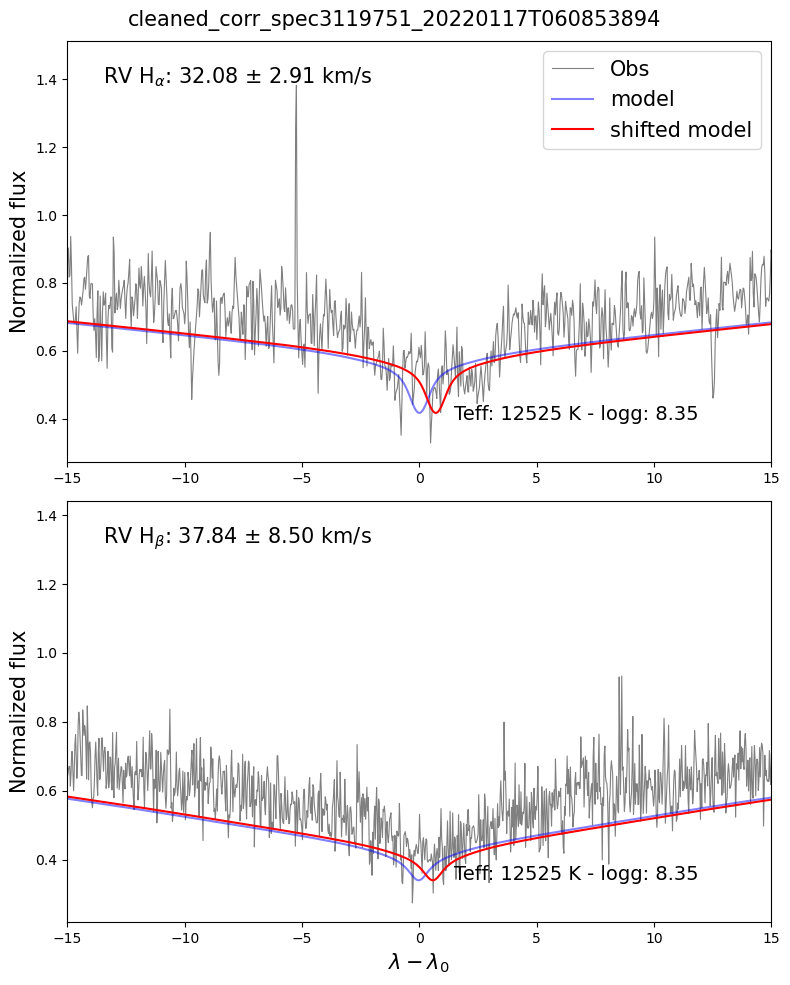

-------------------------------
35.0 31.0
cleaned_corr_spec3119751_20220117T060853894 Ha 35.479999999998924 4.122676873730042
wave 0       6400.002329
1       6400.035393
2       6400.068457
3       6400.101521
4       6400.134585
           ...     
7254    6639.848669
7255    6639.881733
7256    6639.914797
7257    6639.947861
7258    6639.980925
Name: wave, Length: 7259, dtype: float64
cleaned_corr_spec3119751_20220117T060853894 Hb 32.83999999999911 6.719076937013598
wave 0       4790.009491
1       4790.037212
2       4790.064932
3       4790.092653
4       4790.120373
           ...     
9374    5049.888650
9375    5049.916370
9376    5049.944091
9377    5049.971811
9378    5049.999532
Name: wave, Length: 9379, dtype: float64


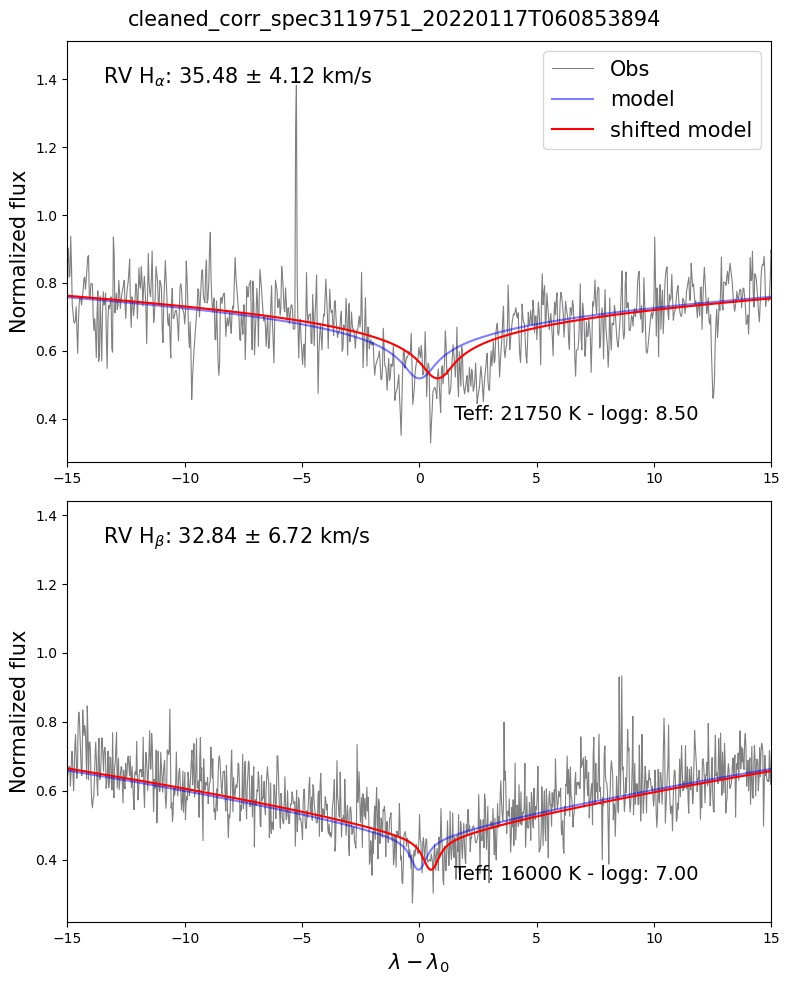

-------------------------------
Datos de ajuste (GF y MJ) guardados para: cleaned_corr_spec3119751_20220117T060853894
47.0 31.0
cleaned_corr_spec4498324_20251229T074925010 Ha 46.67999999999937 2.0592936181977093
wave 0       6400.016817
1       6400.051976
2       6400.087135
3       6400.122293
4       6400.157941
           ...     
6796    6639.824885
6797    6639.860044
6798    6639.895691
6799    6639.930850
6800    6639.966009
Name: wave, Length: 6801, dtype: float64
cleaned_corr_spec4498324_20251229T074925010 Hb 32.479999999999116 4.093767966604461
wave 0       4790.023702
1       4790.053002
2       4790.082789
3       4790.112088
4       4790.141387
           ...     
8835    5049.858667
8836    5049.888455
8837    5049.917754
8838    5049.947053
8839    5049.976352
Name: wave, Length: 8840, dtype: float64


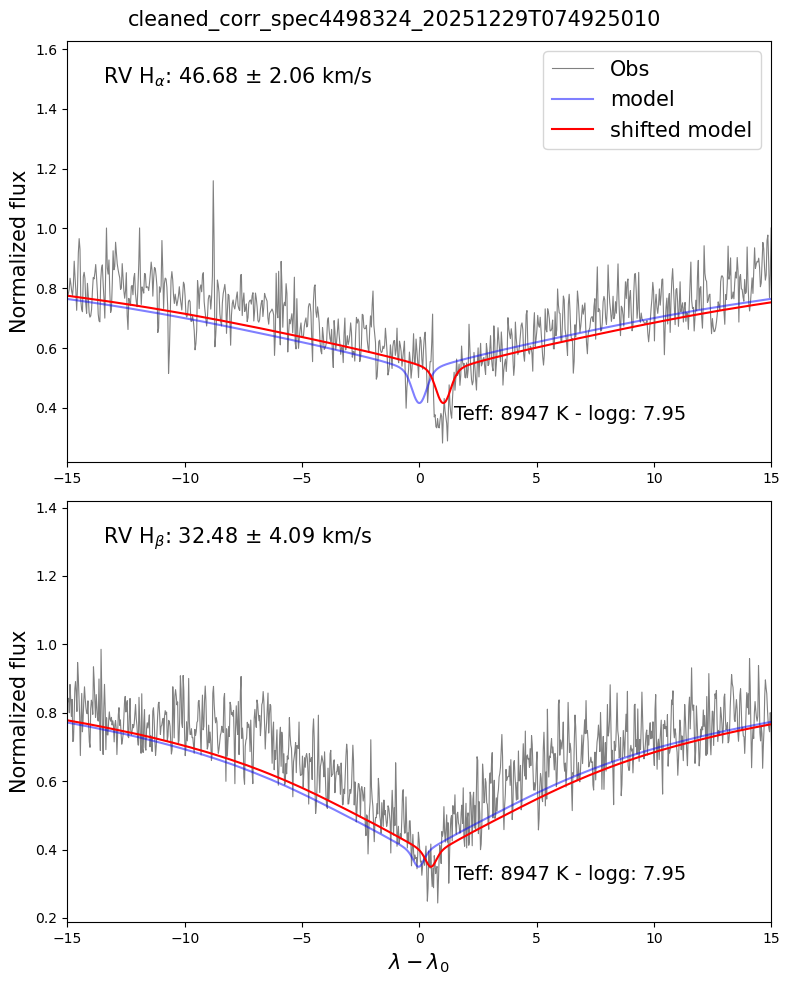

-------------------------------
47.0 31.0
cleaned_corr_spec4498324_20251229T074925010 Ha 46.67999999999937 1.9167744446571782
wave 0       6400.016817
1       6400.051976
2       6400.087135
3       6400.122293
4       6400.157941
           ...     
6796    6639.824885
6797    6639.860044
6798    6639.895691
6799    6639.930850
6800    6639.966009
Name: wave, Length: 6801, dtype: float64
cleaned_corr_spec4498324_20251229T074925010 Hb 28.759999999999195 3.7408783693586494
wave 0       4790.023702
1       4790.053002
2       4790.082789
3       4790.112088
4       4790.141387
           ...     
8835    5049.858667
8836    5049.888455
8837    5049.917754
8838    5049.947053
8839    5049.976352
Name: wave, Length: 8840, dtype: float64


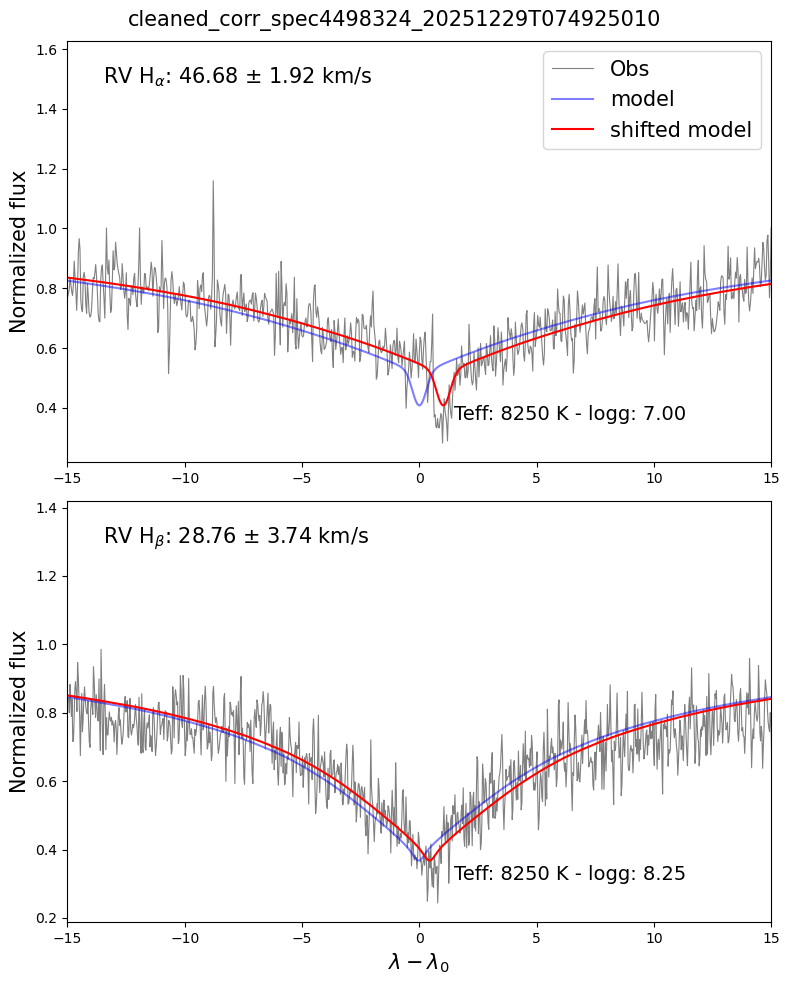

-------------------------------
Datos de ajuste (GF y MJ) guardados para: cleaned_corr_spec4498324_20251229T074925010
8.0 1.0
cleaned_corr_spec4498660_20251026T051345440 Ha 8.240000000000009 1.7428033094665176
wave 0       6400.0156
1       6400.0510
2       6400.0854
3       6400.1206
4       6400.1560
          ...    
6829    6639.8535
6830    6639.8887
6831    6639.9240
6832    6639.9590
6833    6639.9940
Name: wave, Length: 6834, dtype: float64
cleaned_corr_spec4498660_20251026T051345440 Hb 3.879999999999299 3.973205383788448
wave 0       4790.0254
1       4790.0540
2       4790.0835
3       4790.1123
4       4790.1410
          ...    
8964    5049.8813
8965    5049.9100
8966    5049.9395
8967    5049.9683
8968    5049.9970
Name: wave, Length: 8969, dtype: float64


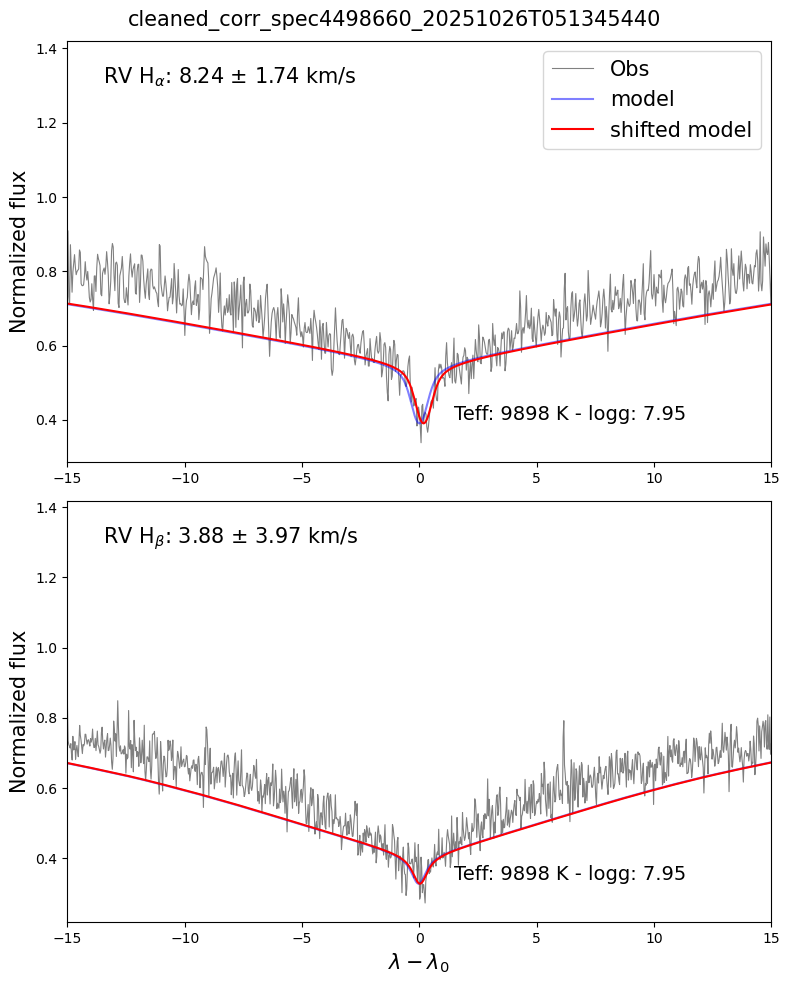

-------------------------------
8.0 1.0
cleaned_corr_spec4498660_20251026T051345440 Ha 8.240000000000009 1.6198748328882808
wave 0       6400.0156
1       6400.0510
2       6400.0854
3       6400.1206
4       6400.1560
          ...    
6829    6639.8535
6830    6639.8887
6831    6639.9240
6832    6639.9590
6833    6639.9940
Name: wave, Length: 6834, dtype: float64
cleaned_corr_spec4498660_20251026T051345440 Hb 1.0799999999993588 3.9803592533497536
wave 0       4790.0254
1       4790.0540
2       4790.0835
3       4790.1123
4       4790.1410
          ...    
8964    5049.8813
8965    5049.9100
8966    5049.9395
8967    5049.9683
8968    5049.9970
Name: wave, Length: 8969, dtype: float64


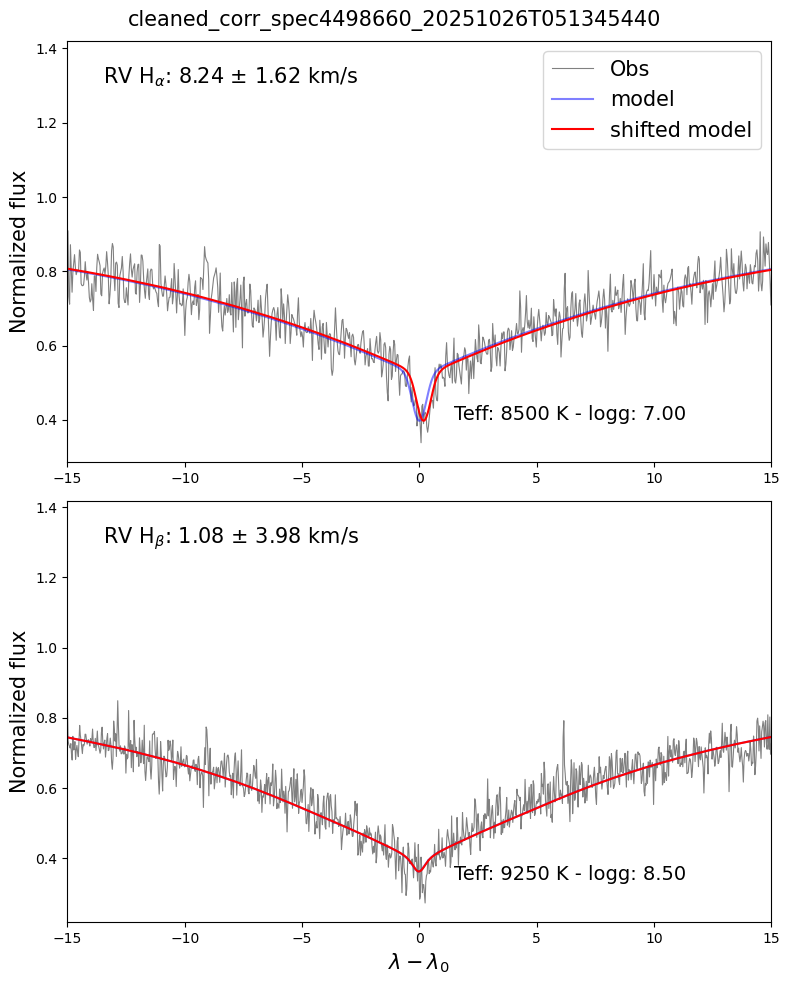

-------------------------------
Datos de ajuste (GF y MJ) guardados para: cleaned_corr_spec4498660_20251026T051345440
14.0 4.0
cleaned_corr_spec4498579_20260315T085226383 Ha 14.359999999999353 2.6951583360869606
wave 0       6400.0034
1       6400.0386
2       6400.0737
3       6400.1090
4       6400.1440
          ...    
6813    6639.8550
6814    6639.8900
6815    6639.9253
6816    6639.9604
6817    6639.9956
Name: wave, Length: 6818, dtype: float64
cleaned_corr_spec4498579_20260315T085226383 Hb 4.279999999999568 2.850726569265648
wave 0       4790.0200
1       4790.0490
2       4790.0780
3       4790.1074
4       4790.1367
          ...    
8897    5049.8570
8898    5049.8860
8899    5049.9155
8900    5049.9450
8901    5049.9736
Name: wave, Length: 8902, dtype: float64


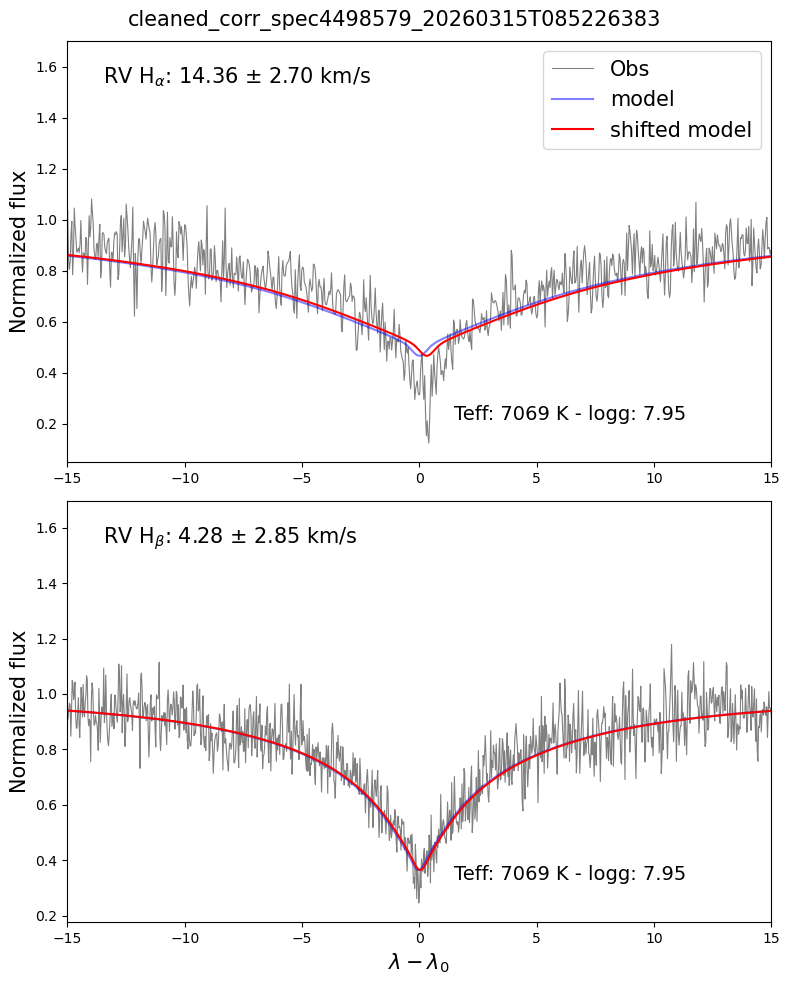

-------------------------------
14.0 4.0
cleaned_corr_spec4498579_20260315T085226383 Ha 14.359999999999353 2.516057959707864
wave 0       6400.0034
1       6400.0386
2       6400.0737
3       6400.1090
4       6400.1440
          ...    
6813    6639.8550
6814    6639.8900
6815    6639.9253
6816    6639.9604
6817    6639.9956
Name: wave, Length: 6818, dtype: float64
cleaned_corr_spec4498579_20260315T085226383 Hb 4.439999999999564 2.7844457110417813
wave 0       4790.0200
1       4790.0490
2       4790.0780
3       4790.1074
4       4790.1367
          ...    
8897    5049.8570
8898    5049.8860
8899    5049.9155
8900    5049.9450
8901    5049.9736
Name: wave, Length: 8902, dtype: float64


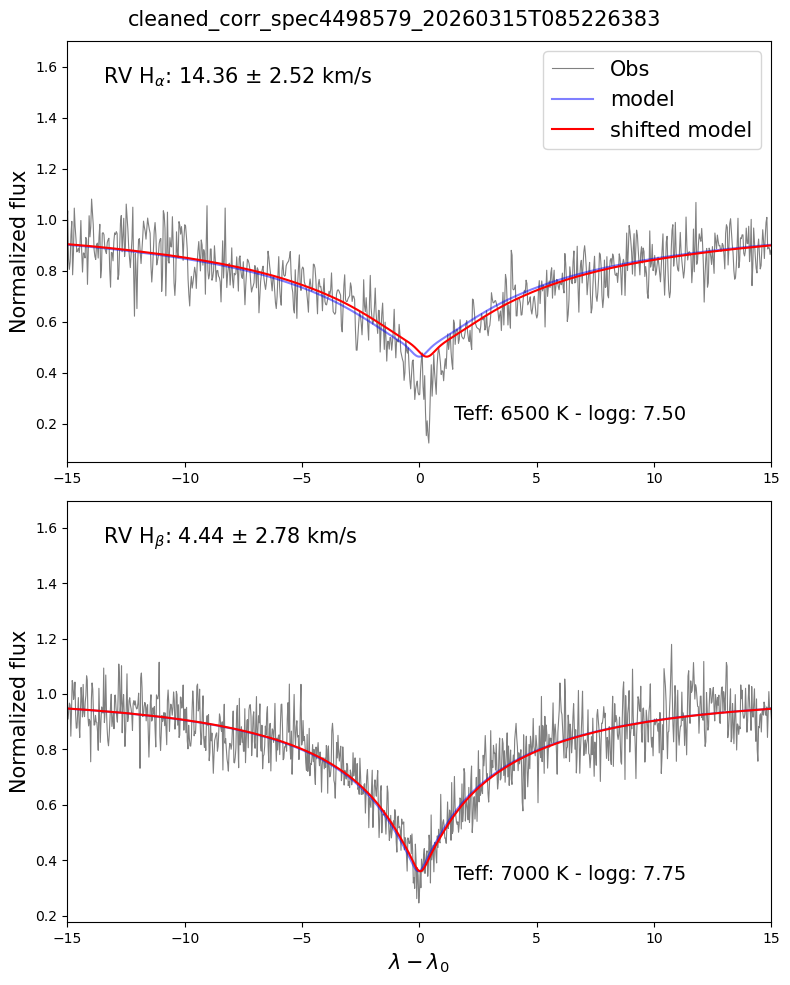

-------------------------------
Datos de ajuste (GF y MJ) guardados para: cleaned_corr_spec4498579_20260315T085226383
-14.0 -16.0
cleaned_corr_spec4498777_20260326T090523186 Ha -15.920000000000812 2.280288978728331
wave 0       6400.0120
1       6400.0474
2       6400.0825
3       6400.1177
4       6400.1523
          ...    
6847    6639.8540
6848    6639.8890
6849    6639.9243
6850    6639.9590
6851    6639.9940
Name: wave, Length: 6852, dtype: float64
cleaned_corr_spec4498777_20260326T090523186 Hb -17.240000000000613 3.0323898245549286
wave 0       4790.0220
1       4790.0513
2       4790.0800
3       4790.1094
4       4790.1380
          ...    
8940    5049.8696
8941    5049.8990
8942    5049.9277
8943    5049.9570
8944    5049.9860
Name: wave, Length: 8945, dtype: float64


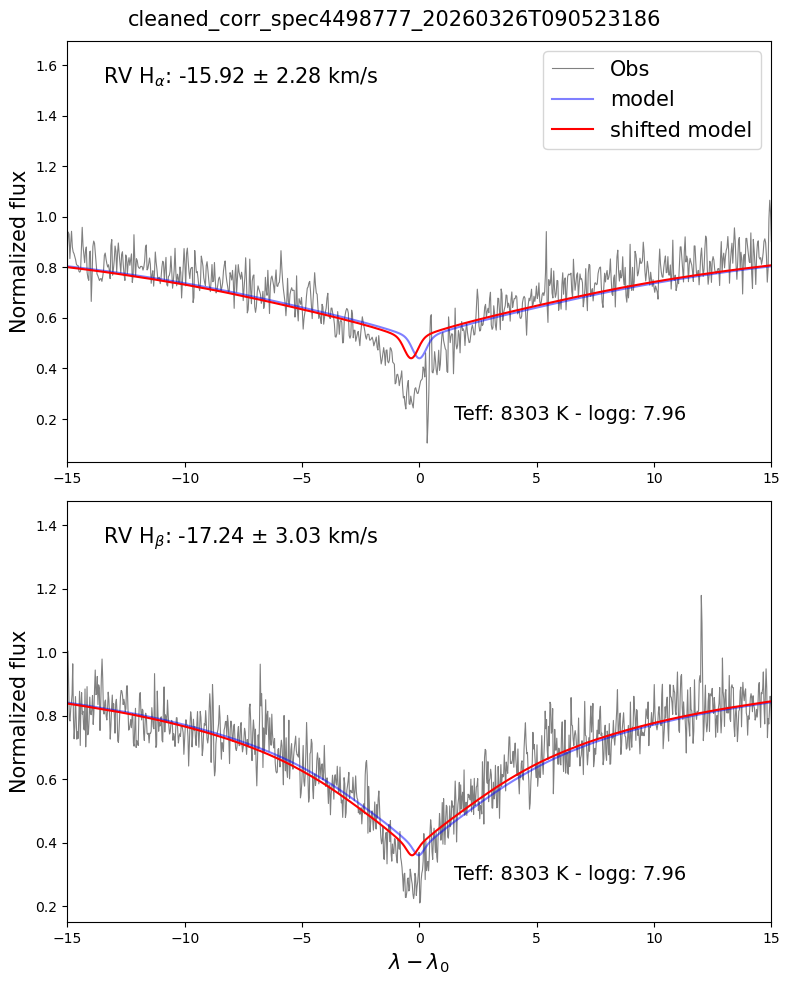

-------------------------------
-14.0 -16.0
cleaned_corr_spec4498777_20260326T090523186 Ha -14.280000000000847 2.495453068056024
wave 0       6400.0120
1       6400.0474
2       6400.0825
3       6400.1177
4       6400.1523
          ...    
6847    6639.8540
6848    6639.8890
6849    6639.9243
6850    6639.9590
6851    6639.9940
Name: wave, Length: 6852, dtype: float64
cleaned_corr_spec4498777_20260326T090523186 Hb -16.52000000000063 2.9401349922730637
wave 0       4790.0220
1       4790.0513
2       4790.0800
3       4790.1094
4       4790.1380
          ...    
8940    5049.8696
8941    5049.8990
8942    5049.9277
8943    5049.9570
8944    5049.9860
Name: wave, Length: 8945, dtype: float64


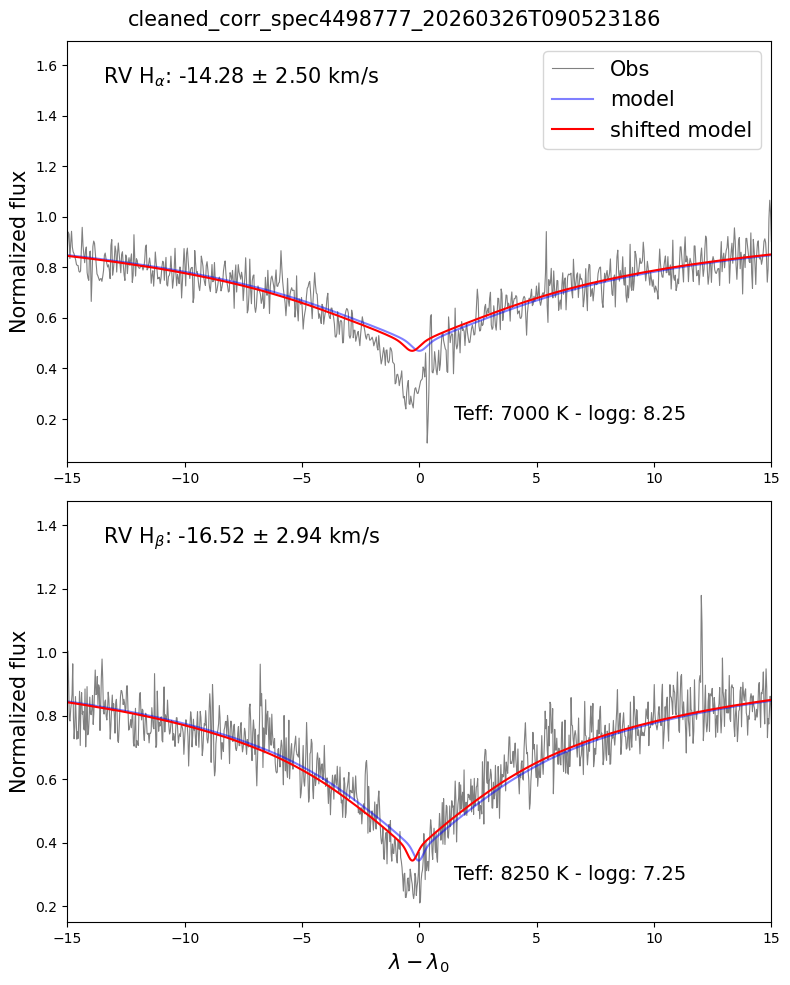

-------------------------------
Datos de ajuste (GF y MJ) guardados para: cleaned_corr_spec4498777_20260326T090523186
67.0 71.0
cleaned_corr_spec126412_20021231T010058267 Ha 67.31999999999935 2.1942174278287183
wave 0       6400.0220
1       6400.0560
2       6400.0903
3       6400.1245
4       6400.1580
          ...    
7036    6639.8320
7037    6639.8660
7038    6639.9004
7039    6639.9346
7040    6639.9683
Name: wave, Length: 7041, dtype: float64
cleaned_corr_spec126412_20021231T010058267 Hb 69.75999999999917 4.2077833411192795
wave 0       4790.0093
1       4790.0366
2       4790.0645
3       4790.0920
4       4790.1196
          ...    
9402    5049.8740
9403    5049.9014
9404    5049.9290
9405    5049.9570
9406    5049.9844
Name: wave, Length: 9407, dtype: float64


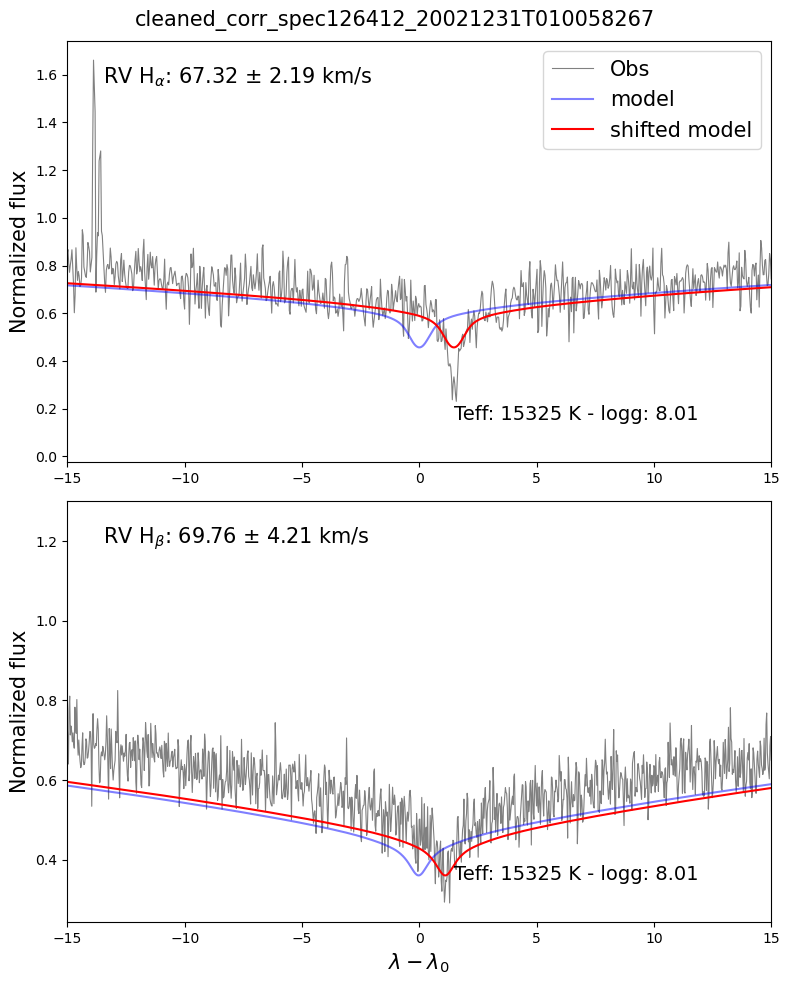

-------------------------------
67.0 71.0
cleaned_corr_spec126412_20021231T010058267 Ha 67.35999999999936 2.0785326718553283
wave 0       6400.0220
1       6400.0560
2       6400.0903
3       6400.1245
4       6400.1580
          ...    
7036    6639.8320
7037    6639.8660
7038    6639.9004
7039    6639.9346
7040    6639.9683
Name: wave, Length: 7041, dtype: float64
cleaned_corr_spec126412_20021231T010058267 Hb 70.95999999999916 3.7796687924804853
wave 0       4790.0093
1       4790.0366
2       4790.0645
3       4790.0920
4       4790.1196
          ...    
9402    5049.8740
9403    5049.9014
9404    5049.9290
9405    5049.9570
9406    5049.9844
Name: wave, Length: 9407, dtype: float64


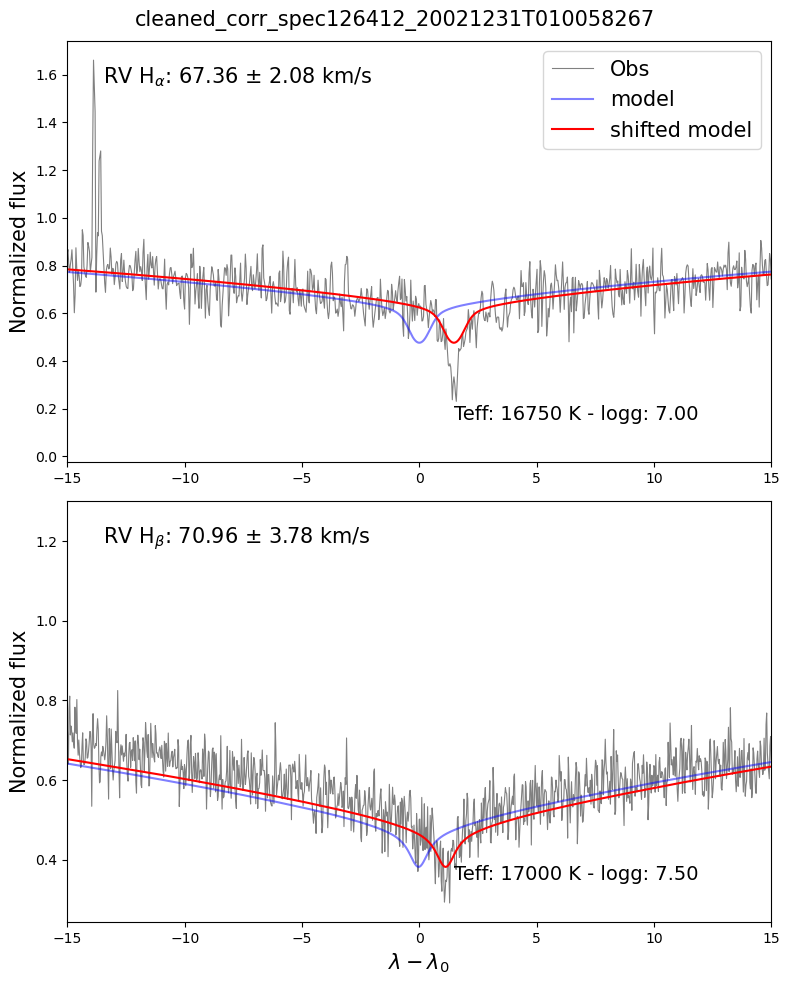

-------------------------------
Datos de ajuste (GF y MJ) guardados para: cleaned_corr_spec126412_20021231T010058267

¡Proceso terminado! Todos los resultados se exportaron con éxito a 'resultados_DAFit_individuales_22.csv'.


In [10]:
import pandas as pd

# 1. Definir rutas (Leemos tu archivo base central, pero la salida es unificada)
path_central = 'initial_guesses_22.csv'
path_salida = 'resultados_DAFit_individuales_22.csv'  # <- Tu archivo consolidado

# Cargar el archivo central original (sirve solo como plantilla base en memoria)
df_central = pd.read_csv(path_central, sep=',')

columna_estrella = 'nombre_1'

# 2. Inicializar las columnas adaptadas para AMBOS métodos (_GF y _MJ) si no existen
columnas_nuevas = [
    'rv_Ha_GF', 'rv_Hb_GF', 'erv_Ha_GF', 'erv_Hb_GF', 'chi2_Ha_GF', 'chi2_Hb_GF',
    'rv_Ha_MJ', 'rv_Hb_MJ', 'erv_Ha_MJ', 'erv_Hb_MJ', 'chi2_Ha_MJ', 'chi2_Hb_MJ'
]
for col in columnas_nuevas:
    if col not in df_central.columns:
        df_central[col] = None

# 3. Correr el bucle recopilando y guardando los datos de ambos métodos
for nombre in nombres_info_list:
    
    # Verificar si la estrella existe en el archivo central
    if nombre not in df_central[columna_estrella].values:
        print(f"Advertencia: {nombre} no está en el archivo central. Saltando...")
        continue
    
    # Localizar la fila de la estrella una sola vez para esta iteración
    idx = df_central[columna_estrella] == nombre
    
    # --- AJUSTE MÉTODO 1: GF ---
    try:
        rvs_gf, ervs_gf, chi2s_gf = rv_thin(nombre, use='GF')
        
        df_central.loc[idx, 'rv_Ha_GF'] = rvs_gf[0]
        df_central.loc[idx, 'rv_Hb_GF'] = rvs_gf[1]
        df_central.loc[idx, 'erv_Ha_GF'] = ervs_gf[0]
        df_central.loc[idx, 'erv_Hb_GF'] = ervs_gf[1]
        df_central.loc[idx, 'chi2_Ha_GF'] = chi2s_gf[0]
        df_central.loc[idx, 'chi2_Hb_GF'] = chi2s_gf[1]
    except Exception as e:
        print(f"Error en ajuste GF para {nombre}: {e}")

    # --- AJUSTE MÉTODO 2: MJ ---
    try:
        rvs_mj, ervs_mj, chi2s_mj = rv_thin(nombre, use='MJ')
        
        df_central.loc[idx, 'rv_Ha_MJ'] = rvs_mj[0]
        df_central.loc[idx, 'rv_Hb_MJ'] = rvs_mj[1]
        df_central.loc[idx, 'erv_Ha_MJ'] = ervs_mj[0]
        df_central.loc[idx, 'erv_Hb_MJ'] = ervs_mj[1]
        df_central.loc[idx, 'chi2_Ha_MJ'] = chi2s_mj[0]
        df_central.loc[idx, 'chi2_Hb_MJ'] = chi2s_mj[1]
    except Exception as e:
        print(f"Error en ajuste MJ para {nombre}: {e}")
        
    print(f"Datos de ajuste (GF y MJ) guardados para: {nombre}")

# 4. Guardar los cambios finales en el archivo unificado sin tocar el inicial
df_central.to_csv(path_salida, index=False, sep=',')
print(f"\n¡Proceso terminado! Todos los resultados se exportaron con éxito a '{path_salida}'.")